# 07 — Ön Eğitim (Pretraining) ve Fine-Tuning: Hazır Modellerle, LoRA ile ve RAG'e Göz Kırparak

**Önkoşul:** 01-06. 01-05'te parçaları **sıfırdan** kurduk, 06'da hazır modellerin içine baktık. Bu notebook'ta yön bir kez daha değişiyor: artık kod yazmaktan çok **modelleri kullanıyoruz**. Farklı modelleri yan yana koyup ne yaptıklarına bakacağız; sıfırdan yazacağımız tek şey ~10 satırlık bir LoRA katmanı (çünkü "neden bu kadar az parametre yetiyor?" sorusunun cevabı orada).

### Bu notebook'un 4 ana fikri

1. **Pretraining bir "ödevdir".** GPT'ye "sıradaki token'ı tahmin et", BERT'e "maskelenmiş token'ı bul", T5'e "silinen parçayı üret" deniyor. Mimari aynı, ödev farklı; modelin yeteneği ödevden çıkıyor. Pretraining'i biz yapmayacağız (aylar, binlerce GPU), ama hazır modellerin **sürpriz (loss)** ve tahminlerine bakarak ödevin ne öğrettiğini göreceğiz.
2. **Fine-tuning = aynı ödev, yeni ve küçük veri.** Base model ile Instruct modelini karşılaştırarak fine-tuning'in modele ne kattığını (ve neyi götürdüğünü) göreceğiz.
3. **LoRA:** Bütün ağırlığı değiştirmek yerine yanına küçük bir düzeltme öğrenmek (`W + B·A`). Çekirdeğini elle yazıp `peft` ile birebir aynı sonucu verdiğini göreceğiz; gerçek eğitimi `peft` + `Trainer` yapacak.
4. **Model bilmediği bir şeyi nasıl öğrenir?** Ya bilgiyi **ağırlığa yazarız** (fine-tune) ya da **prompt'a bağlam koyarız** (RAG'in özü). İkisini aynı sorularda deneyeceğiz. Amaç "hangisi kazandı" değil, "hangisi ne için iyi" sorusunu deneyle görmek.

Her bölümde önce **sezgi**, sonra **kod**, sonra **"Ne gördük?"** geliyor. "(İsteğe bağlı)" kısımları ilk okumada atlayabilirsin. Matematik hafif tutuldu.

### Kullanacağımız modeller

| Model | Boyut | Ne için |
|---|---|---|
| `gpt2` | 124M, İngilizce | sonraki-token ödevi (06'dan tanıdık) |
| `Qwen/Qwen2.5-0.5B` (base) | 494M, çok dilli (Türkçe dahil) | sonraki-token ödevi + fine-tune edeceğimiz model |
| `Qwen/Qwen2.5-0.5B-Instruct` | 494M | aynı model + talimat fine-tuning'i (base ile karşılaştırma, RAG'de "okuyucu") |
| `bert-base-uncased` | 110M, İngilizce | masked LM |
| `dbmdz/bert-base-turkish-cased` | 110M, Türkçe | masked LM (Türkçe'ye özel) |
| `bert-base-multilingual-cased` | 178M, 100+ dil | masked LM (çok dilli) |
| `t5-small` | 60M | sadece tokenizer: span-corruption verisi nasıl kuruluyor |
| `intfloat/multilingual-e5-small` | 118M | embedding modeli: RAG'deki "bulucu" (retriever) |

**Not (internet):** İlk çalıştırmada modeller Hugging Face'ten iniyor (toplam ~4 GB; `gpt2` ve `bert-base-uncased` 06'dan önbellekte olabilir). Sonrasında önbellekten geliyor.

**Not (kurulum):** `peft` kütüphanesi gerekiyor. Yoksa terminalde `pip install peft` (ilk hücre kontrol ediyor).

**Not (Mac):** `Trainer` Apple GPU'sunu (MPS) kendisi seçer. Eğitim hücresinde bir MPS hatası alırsan `FORCE_CPU = True` yapman yeterli (ilk hücrede).

**Bellek notu:** 0.5B'lik bir model float32'de ~2 GB tutar. Bu yüzden `qwen_base`'i 4. bölümde işimiz bitince bellekten siliyoruz, Instruct modelini `bfloat16` (yarı bellek) yüklüyoruz. Toplamda ~5 GB RAM yeter; belleğin dar ise yeni bir modeli yüklemeden önce eskisini `del` + `gc.collect()` ile boşalt.

**Reprodüksiyon notu:** `peft` bir modeli **yerinde değiştirir** (`get_peft_model` orijinal modele LoRA katmanlarını takar). Bu yüzden eğitim fonksiyonu (`lora_egit`) her seferinde modeli **baştan yükler**; aynı model nesnesini iki kez sarmalamıyoruz. Kullanılan global isimler: `gpt`, `tok_gpt`, `tok_q`, `qwen_inst`, `tok_qi`, `lora_m`, `e5`, `tok_e5`, `FACTS`, `REVERSE`, `GENERAL`, `SETLER`, `PASAJLAR`, `P` ve fonksiyonlar (`kutu`, `ok_ciz`, `nll_per_token`, `ppl_bpc`, `cevapla`, `sohbet`, `gomme`, `getir`, `rag_prompt`, `lora_egit`, `puanla`, `dogru`). Egzersizlerde bunları **ezme**.

In [3]:
import time, math, os, gc, copy, importlib.util
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import torch
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModel, pipeline
from dotenv import load_dotenv
load_dotenv()   # .env içindeki HF_TOKEN (varsa) indirmeleri hızlandırır

transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()

FORCE_CPU = False    # Mac'te eğitim sırasında MPS hatası alırsan True yap

HAS_PEFT = importlib.util.find_spec("peft") is not None
if HAS_PEFT:
    import peft
    from peft import LoraConfig, get_peft_model
cihaz = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("torch", torch.__version__, "| transformers", transformers.__version__,
      "| peft", peft.__version__ if HAS_PEFT else "YOK  ->  terminalde: pip install peft")
print("cihaz:", cihaz)

torch 2.13.0 | transformers 5.17.0 | peft 0.21.1
cihaz: mps


In [4]:
# ---- Şekil çizim yardımcıları (akış şemaları için) ----
def kutu(ax, x, y, w, h, metin, renk="#dbe9f6", kenar="#3b6ea5", fs=10, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=renk, ec=kenar, lw=1.6))
    ax.text(x + w/2, y + h/2, metin, ha="center", va="center", fontsize=fs,
            fontweight="bold" if bold else "normal")

def ok_ciz(ax, x1, y1, x2, y2, renk="#444", ls="-"):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color=renk, lw=1.8, linestyle=ls))

In [5]:
# ---- Model yardımcıları ----
EOT = "<|endoftext|>"     # hem GPT-2 hem Qwen'de "metin başı/sonu" token'ı

def nll_per_token(model, tok, metin):
    """Metindeki her token için 'sürpriz' = -log(modelin ona verdiği olasılık).
    Başa <|endoftext|> koyuyoruz ki İLK token da tahmin edilmiş olsun."""
    ids = [tok.convert_tokens_to_ids(EOT)] + tok(metin, add_special_tokens=False).input_ids
    x = torch.tensor([ids], device=model.device)
    with torch.no_grad():
        logits = model(x).logits[0, :-1].float()
    nll = torch.nn.functional.cross_entropy(logits, x[0, 1:], reduction="none")
    return tok.convert_ids_to_tokens(ids[1:]), nll.cpu()

def ppl_bpc(model, tok, metinler):
    """Bir metin listesi için: token/karakter, perplexity (token başına), bit/karakter.
    Farklı tokenizer'lı modelleri kıyaslamak için tek adil ölçü bit/karakter (bpc)."""
    toplam_nll, n_tok, n_kar = 0.0, 0, 0
    for m in metinler:
        _, nll = nll_per_token(model, tok, m)
        toplam_nll += nll.sum().item(); n_tok += len(nll); n_kar += len(m)
    return dict(tok_kar=n_tok / n_kar, ppl=math.exp(toplam_nll / n_tok), bpc=toplam_nll / math.log(2) / n_kar)

def cevapla(model, tok, prompt, n=28, ilk_satir=True):
    """Ham prompt'un devamını greedy üretir."""
    ids = tok(prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        out = model.generate(**ids, max_new_tokens=n, do_sample=False, pad_token_id=tok.eos_token_id)
    s = tok.decode(out[0][ids.input_ids.shape[1]:], skip_special_tokens=True).strip()
    return s.split("\n")[0].strip() if ilk_satir else s

def sohbet(model, tok, soru, baglam=None, n=40):
    """Instruct modelini sohbet şablonuyla çağırır. baglam verilirse 'sadece bunu kullan' der."""
    if baglam:
        sistem = "Sadece verilen bilgiye dayanarak, kısa ve tek cümleyle cevap ver. Bilgi yoksa 'Bilmiyorum' de."
        kullanici = f"Bilgi: {baglam}\n\nSoru: {soru}"
    else:
        sistem, kullanici = "Kısa ve tek cümleyle cevap ver.", soru
    p = tok.apply_chat_template([{"role": "system", "content": sistem}, {"role": "user", "content": kullanici}],
                                tokenize=False, add_generation_prompt=True)
    ids = tok(p, return_tensors="pt").to(model.device)
    with torch.no_grad():
        out = model.generate(**ids, max_new_tokens=n, do_sample=False)
    return tok.decode(out[0][ids.input_ids.shape[1]:], skip_special_tokens=True).strip()

## 1) Büyük resim: bir modelin hayatı iki aşamadan oluşuyor

### Sezgi

Bir dil modelini önce **okuma yazma öğrenen bir çocuğa** benzet: yıllarca, her türlü metni okuyor; kimse ona "şunu öğren" demiyor, sadece "sıradaki kelime ne olacak?" oyununu oynuyor. Bu **pretraining**: sonunda dili, dünya bilgisini, biraz da muhakemeyi bir kenarda taşıyan genel bir model çıkıyor (**base model**).

Sonra bu genel modele **belirli bir iş** öğretmek istiyoruz: talimat takip etmek, tıbbi rapor özetlemek, senin şirketinin tonunda yazmak. Bu **fine-tuning**: aynı oyunu (sonraki token) oynatmaya devam ediyoruz ama bu sefer **küçük ve hedefe özel** bir veriyle.

Bir üçüncü yol daha var ve tezin için özellikle önemli: modelin ağırlıklarına hiç dokunmadan, ihtiyacı olan bilgiyi **prompt'un içine koymak**. RAG'in özü bu; 5. bölümde ikisini yarıştıracağız.

Aşağıdaki şema bu iki yolu gösteriyor.

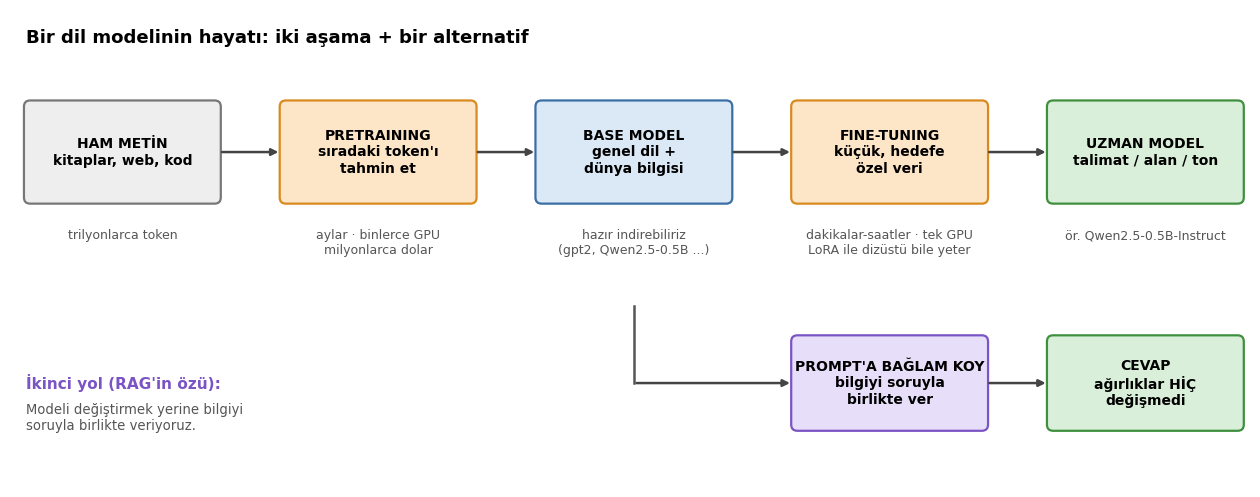

In [6]:
def draw_lifecycle(save="pretrain_finetune_pipeline.png"):
    fig, ax = plt.subplots(figsize=(16, 6.2))
    ax.set_xlim(0, 16); ax.set_ylim(0, 6.2); ax.axis("off")
    ust = 3.7
    adimlar = [
        (0.2,  "HAM METİN\nkitaplar, web, kod", "#eeeeee", "#777777", "trilyonlarca token"),
        (3.5,  "PRETRAINING\nsıradaki token'ı\ntahmin et", "#fde6c8", "#d98a1f", "aylar · binlerce GPU\nmilyonlarca dolar"),
        (6.8,  "BASE MODEL\ngenel dil +\ndünya bilgisi", "#dbe9f6", "#3b6ea5", "hazır indirebiliriz\n(gpt2, Qwen2.5-0.5B ...)"),
        (10.1, "FINE-TUNING\nküçük, hedefe\nözel veri", "#fde6c8", "#d98a1f", "dakikalar-saatler · tek GPU\nLoRA ile dizüstü bile yeter"),
        (13.4, "UZMAN MODEL\ntalimat / alan / ton", "#d9efd9", "#3f8f3f", "ör. Qwen2.5-0.5B-Instruct"),
    ]
    for x, t, r, k, alt in adimlar:
        kutu(ax, x, ust, 2.5, 1.3, t, renk=r, kenar=k, fs=10, bold=True)
        ax.text(x + 1.25, ust - 0.35, alt, ha="center", va="top", fontsize=9, color="#555")
    for x in (2.7, 6.0, 9.3, 12.6):
        ok_ciz(ax, x, ust + 0.65, x + 0.8, ust + 0.65)
    # alt şerit: ağırlığa dokunmadan yol
    ax.plot([8.05, 8.05], [ust - 1.35, 1.35], color="#555", lw=1.8)
    ok_ciz(ax, 8.05, 1.35, 10.1, 1.35)
    kutu(ax, 10.1, 0.75, 2.5, 1.2, "PROMPT'A BAĞLAM KOY\nbilgiyi soruyla\nbirlikte ver", renk="#e7defa", kenar="#7a54c4", fs=10, bold=True)
    kutu(ax, 13.4, 0.75, 2.5, 1.2, "CEVAP\nağırlıklar HİÇ\ndeğişmedi", renk="#d9efd9", kenar="#3f8f3f", fs=10, bold=True)
    ok_ciz(ax, 12.6, 1.35, 13.4, 1.35)
    ax.text(0.2, 1.35, "İkinci yol (RAG'in özü):", fontsize=11, fontweight="bold", color="#7a54c4", va="center")
    ax.text(0.2, 0.9, "Modeli değiştirmek yerine bilgiyi\nsoruyla birlikte veriyoruz.", fontsize=9.5, color="#555", va="center")
    ax.text(0.2, 5.95, "Bir dil modelinin hayatı: iki aşama + bir alternatif", fontsize=13, fontweight="bold", va="top")
    plt.savefig(save, dpi=130, bbox_inches="tight"); plt.show()
draw_lifecycle()

**Ne gördük?**

- Üst şerit **pahalı, tek seferlik** kısım (pretraining) ve **ucuz, tekrarlanabilir** kısım (fine-tuning). Biz sadece ortadaki hazır base modeli indirip kullanıyoruz.
- Alt şerit üçüncü bir yol: modele **hiç dokunmadan** ihtiyacı olan bilgiyi soruyla birlikte vermek. 5. bölümde bu yolu, üst şeritteki fine-tune ile aynı sorularda yarıştıracağız.

## 2) Pretraining: aynı mimari, üç farklı "ödev"

### Sezgi

06'da gördük: GPT-2 ile BERT arasındaki fark **kimin kimi görebildiği** (causal mask). Ama asıl fark **ödevde**. Model ne öğreneceğini ödevden alıyor:

- **GPT (causal LM):** "Şu ana kadar gördüklerine bakarak **sıradaki** token'ı tahmin et."
- **BERT (masked LM):** "Cümlenin bazı token'ları `[MASK]` ile örtüldü; **sağına ve soluna bakarak** onları bul."
- **T5 (span corruption):** "Cümlenin bazı parçaları silindi; **silinen parçaları** sırayla üret."

Bir modelin ödevde ne kadar iyi olduğunu tek bir sayıyla ölçüyoruz: **sürpriz** (loss). Modelin doğru token'a verdiği olasılık düşükse "şaşırıyor" demektir: `sürpriz = −log(olasılık)`. Ortalama sürprizin üssü **perplexity**: "model her adımda kabaca kaç seçenek arasında kalıyor?" Perplexity 15 ise model her token'da yaklaşık 15 eşit olası aday arasında kararsız.

### 2a) GPT-2: bir cümlede token token sürpriz

Aynı kelimeler, biri düzgün sırada biri karışık. Dilbilgisini "bilen" bir modelin ikisine tepkisi farklı olmalı.

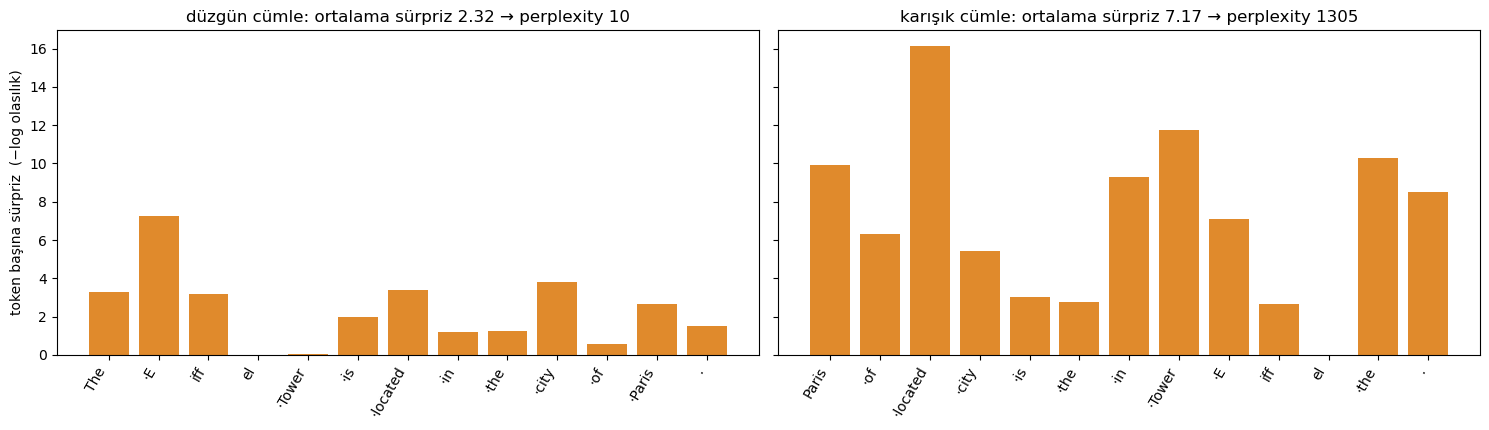

In [7]:
tok_gpt = AutoTokenizer.from_pretrained("gpt2")
gpt = AutoModelForCausalLM.from_pretrained("gpt2").eval()

cumleler = {
    "düzgün cümle":  "The Eiffel Tower is located in the city of Paris.",
    "karışık cümle": "Paris of located city is the in Tower Eiffel the.",
}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), sharey=True)
for ax, (ad, c) in zip(axes, cumleler.items()):
    toks, nll = nll_per_token(gpt, tok_gpt, c)
    ax.bar(range(len(toks)), nll.numpy(), color="#e08a2c")
    ax.set_xticks(range(len(toks)))
    ax.set_xticklabels([t.replace("Ġ", "·") for t in toks], rotation=60, ha="right")
    ax.set_title(f"{ad}: ortalama sürpriz {nll.mean():.2f} → perplexity {math.exp(nll.mean()):.0f}")
axes[0].set_ylabel("token başına sürpriz  (−log olasılık)")
plt.tight_layout(); plt.savefig("gpt2_token_surprisal.png", dpi=130); plt.show()

**Ne gördük?**

- **Düzgün cümlede perplexity ~10, karışık cümlede ~1300.** Aynı kelimeler, sadece sıra farklı. Model dil bilgisini ödevden öğrenmiş: kelimeler yerindeyse şaşırmıyor, yerinde değilse çok şaşırıyor.
- Soldaki grafikte en yüksek sütun `E` (Eiffel'in ilk parçası, ~7): model "Eiffel" kelimesini beklemiyordu. Ama **bir kere `E` gelince `iff`, `el`, `Tower` neredeyse bedava** (sürpriz ~0): kelimenin geri kalanı belli. 01'deki alt-kelime (subword) parçalamasının kayba nasıl yansıdığını görüyorsun.
- `Paris` kelimesi bile ~2,7 sürpriz taşıyor (yaklaşık %7 olasılık): "the city of" dedikten sonra hâlâ yüzlerce şehir mümkün.
- Sağdaki karışık cümlede en yüksek sütun `located` (~16): "Paris of" dedikten sonra `located` gelmesi neredeyse imkânsız.

### 2b) Farklı model, farklı dil: perplexity'yi adil kıyaslamak

GPT-2 İngilizce, Qwen2.5 çok dilli (Türkçe dahil) eğitildi. İkisine de aynı anlamda 3 İngilizce ve 3 Türkçe cümle verelim.

Dikkat: iki modelin **tokenizer'ı farklı** (01'i ve 06'daki Egzersiz 4'ü hatırla). Bir cümleyi GPT-2 40 token'a, Qwen 23 token'a bölebilir; token başına perplexity'yi kıyaslamak elmayla armut kıyaslamak olur. Adil ölçü **bit/karakter (bpc)**: modelin metnin her karakterini kodlamak için ortalama kaç bit'e ihtiyaç duyduğu. Düşük olan daha iyi.

In [8]:
EN = ["The capital of France is Paris, and it is known for the Eiffel Tower.",
      "Machine learning models learn patterns from large amounts of data.",
      "Students usually study for their exams in the library."]
TR = ["Türkiye'nin başkenti Ankara'dır ve ülkenin en büyük şehri İstanbul'dur.",
      "Makine öğrenmesi modelleri büyük miktardaki veriden örüntüleri öğrenir.",
      "Öğrenciler sınavlara genellikle kütüphanede çalışır."]

tok_q = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B")
# transformers 5'te modeller varsayılan olarak dosyadaki hassasiyetle (Qwen: bfloat16) yüklenir; biz açıkça float32 istiyoruz
qwen_base = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-0.5B", dtype=torch.float32).eval()

print(f"{'model':<16}{'dil':<5}{'token/karakter':>16}{'perplexity/token':>19}{'bit/karakter':>15}")
for ad, m, t in [("gpt2", gpt, tok_gpt), ("qwen2.5-0.5b", qwen_base, tok_q)]:
    for dil, metinler in [("EN", EN), ("TR", TR)]:
        r = ppl_bpc(m, t, metinler)
        print(f"{ad:<16}{dil:<5}{r['tok_kar']:>16.2f}{r['ppl']:>19.1f}{r['bpc']:>15.2f}")

model           dil    token/karakter   perplexity/token   bit/karakter
gpt2            EN               0.21               35.2           1.06
gpt2            TR               0.54              188.3           4.05
qwen2.5-0.5b    EN               0.21               15.0           0.81
qwen2.5-0.5b    TR               0.34               35.0           1.72


**Ne gördük?**

- **İki modelin İngilizce'deki farkı bile büyük:** GPT-2 1,06, Qwen 0,81 bit/karakter. Qwen çok daha büyük ve çok daha fazla veriyle eğitilmiş; daha az şaşırıyor.
- **Türkçe farkı çok daha keskin:** GPT-2'de Türkçe 4,05 bit/karakter, yani İngilizce'nin **~4 katı**. Qwen'de 1,72, yani **~2 katı**. Türkçe'yi hiç görmemiş bir model bir karakteri kodlamak için çok daha fazla bit'e ihtiyaç duyuyor.
- **token/karakter** sütunu 01 ve 06/Egzersiz 4'ün cevabı: GPT-2 Türkçe'yi 0,54 token/karakterle böler (İngilizce'de 0,21), Qwen 0,34 ile. Yani GPT-2 için Türkçe metin ~2,5 kat daha fazla token demek. Bu hem hesap maliyeti hem bağlam penceresi kaybı.
- **Tuzak:** GPT-2'nin token başına perplexity'si Türkçe'de 188. Ama bu, çok daha küçük token'larla (çoğu tek-iki harf) ölçüldü; tokenizer'ı farklı iki modeli token perplexity'siyle kıyaslamak yanıltır. **Bit/karakter** bunu düzeltiyor.

### 2c) BERT'in ödevi: maskelenmiş kelimeyi bul

BERT eğitilirken token'ların ~%15'i `[MASK]` ile örtülüyor ve model bunları bulmaya çalışıyor. Aşağıda **üç farklı BERT**'e aynı Türkçe cümleleri veriyoruz: İngilizce eğitilmiş, 100+ dille eğitilmiş, sadece Türkçe eğitilmiş. Her birinin ilk 3 tahminine bakıyoruz.

`pipeline("fill-mask")` 06'da elle yaptığımız işi tek satırda yapıyor.

In [9]:
turkce_maske = ["Dün akşam arkadaşlarımla birlikte sinemaya [MASK].",
                "Kitabı okuduktan sonra rafa geri [MASK].",
                "Yağmur yağdığı için şemsiyemi [MASK].",
                "Türkiye'nin başkenti [MASK] şehridir.",
                "Ali her sabah işe otobüsle [MASK]."]
bertler = [("bert-base-uncased", "İngilizce BERT"),
           ("bert-base-multilingual-cased", "çok dilli BERT"),
           ("dbmdz/bert-base-turkish-cased", "Türkçe BERT")]

maske_sonuc = {}
for model_adi, etiket in bertler:
    fm = pipeline("fill-mask", model=model_adi, top_k=3)
    maske_sonuc[etiket] = [[r["token_str"] for r in fm(c)] for c in turkce_maske]
    del fm; gc.collect()

for i, c in enumerate(turkce_maske):
    print(c)
    for _, etiket in bertler:
        print(f"    {etiket:<16}: {maske_sonuc[etiket][i]}")

Dün akşam arkadaşlarımla birlikte sinemaya [MASK].
    İngilizce BERT  : ['##k', '##z', '##gi']
    çok dilli BERT  : ['başladı', 'başlamıştır', 'girdi']
    Türkçe BERT     : ['gittik', 'gittim', 'gidiyoruz']
Kitabı okuduktan sonra rafa geri [MASK].
    İngilizce BERT  : ['##z', '##g', '##f']
    çok dilli BERT  : ['verdi', 'geldi', '##di']
    Türkçe BERT     : ['koydum', 'döndüm', 'attım']
Yağmur yağdığı için şemsiyemi [MASK].
    İngilizce BERT  : ['##n', '##r', '##t']
    çok dilli BERT  : ['vardır', '##dir', 'yoktur']
    Türkçe BERT     : ['aldım', 'açtım', 'çıkardım']
Türkiye'nin başkenti [MASK] şehridir.
    İngilizce BERT  : ['##ye', '##r', '##k']
    çok dilli BERT  : ['İstanbul', 'Trabzon', ',']
    Türkçe BERT     : ['İstanbul', 'Ankara', 've']
Ali her sabah işe otobüsle [MASK].
    İngilizce BERT  : ['##h', '##wa', '##w']
    çok dilli BERT  : ['##şir', '##şmiş', '##çi']
    Türkçe BERT     : ['gidiyor', 'gider', 'gidiyordu']


**Ne gördük?**

- **İngilizce BERT** Türkçe'de sadece `##k`, `##z` gibi **alt-kelime parçaları** üretiyor. Kelime dağarcığında Türkçe kelime yok; `sinemaya` gibi bir şeyi anlamlı parçalara bile bölemiyor. Ödev ("maskeyi bul") aynı, ama model o dili hiç görmedi.
- **Çok dilli BERT** kelime gibi görünen şeyler üretiyor (`başladı`, `verdi`) ama cümleye uymuyor: dil bilgisini yarım yamalak biliyor.
- **Türkçe BERT** doğru **çekimlerle** cevap veriyor: "arkadaşlarımla birlikte sinemaya ..." → `gittik` (biz), "Ali her sabah ... otobüsle" → `gidiyor` (o). Fiilin kişi eki cümlenin öznesiyle uyumlu; bu, maskeli ödevle Türkçe'nin eklemeli yapısının öğrenilebildiğini gösteriyor.
- **"Başkent" cümlesi ilginç:** hem çok dilli hem Türkçe BERT'in ilk tahmini `İstanbul` (Türkçe BERT'te `Ankara` ikinci). Model "bilgiyi" bir olgu olarak değil, **eğitim metinlerindeki sıklık** olarak taşıyor: metinlerde İstanbul daha sık geçiyor. Bu, 5. bölümdeki "model bilmediği şeyi uyduruyor" bulgusunun küçük bir habercisi.

### 2d) T5'in ödevi: silinen parçaları üret (sadece veri nasıl kuruluyor)

T5'in yeteneğini burada denemeyeceğiz (`t5-small` çok küçük, boşluk doldurma çıktıları güvenilir değil). Ama T5'in **eğitim verisi nasıl kuruluyor** görmeye değer: cümleden rastgele parçalar silinip yerine **sentinel** token'lar (`<extra_id_0>`, `<extra_id_1>`, ...) konuyor; hedef, silinen parçaların sırayla yazılmış hali.

In [10]:
from transformers import T5Tokenizer
tok_t5 = T5Tokenizer.from_pretrained("t5-small")

orijinal = "Thank you for inviting me to your party last week."
girdi    = "Thank you <extra_id_0> me to your party <extra_id_1> week."
hedef    = "<extra_id_0> for inviting <extra_id_1> last <extra_id_2>"
print("orijinal cümle :", orijinal)
print("modelin girdisi:", tok_t5.convert_ids_to_tokens(tok_t5(girdi).input_ids))
print("modelin hedefi :", tok_t5.convert_ids_to_tokens(tok_t5(hedef).input_ids))

orijinal cümle : Thank you for inviting me to your party last week.
modelin girdisi: ['▁Thank', '▁you', '<extra_id_0>', '▁me', '▁to', '▁your', '▁party', '<extra_id_1>', '▁week', '.', '</s>']
modelin hedefi : ['<extra_id_0>', '▁for', '▁inviting', '<extra_id_1>', '▁last', '<extra_id_2>', '</s>']


Üç ödevi yan yana koyalım. Şemada **mavi** = modelin girdi olarak gördüğü, **turuncu** = tahmin etmesi gereken.

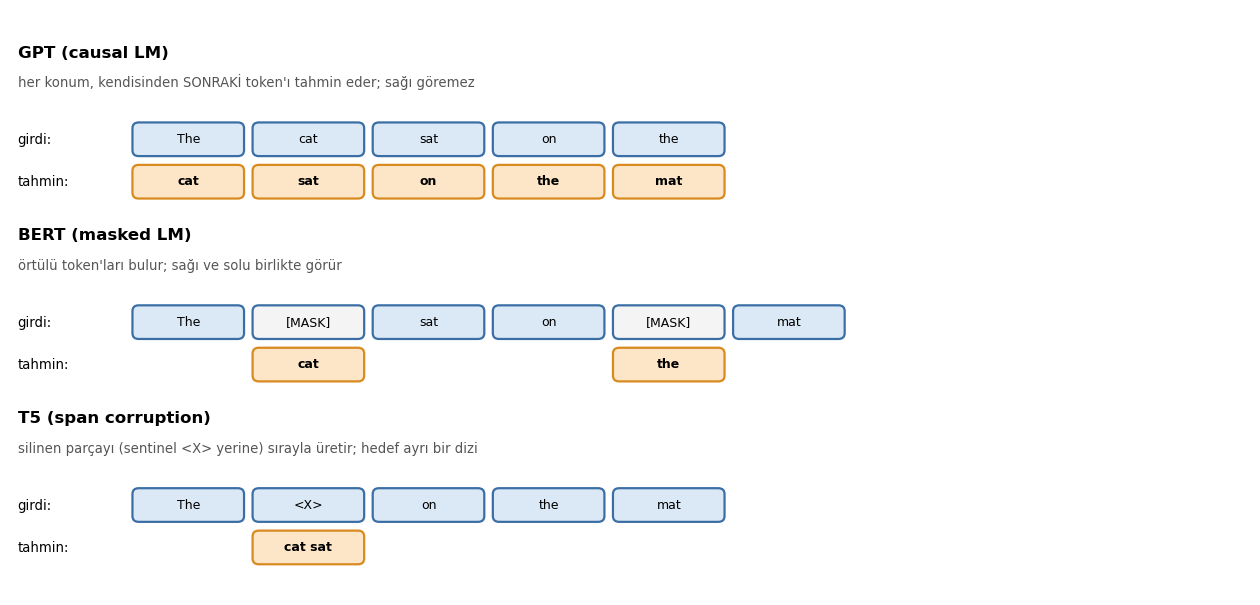

In [11]:
def draw_objectives(save="pretraining_objectives.png"):
    fig, ax = plt.subplots(figsize=(16, 7.6))
    ax.set_xlim(0, 16); ax.set_ylim(-0.6, 7.4); ax.axis("off")
    kel = ["The", "cat", "sat", "on", "the", "mat"]
    def satir(y, girdi, hedef, baslik, aciklama):
        ax.text(0.1, y + 1.75, baslik, fontsize=12, fontweight="bold")
        ax.text(0.1, y + 1.35, aciklama, fontsize=9.5, color="#555")
        ax.text(0.1, y + 0.62, "girdi:", fontsize=9.5, va="center")
        ax.text(0.1, y + 0.05, "tahmin:", fontsize=9.5, va="center")
        for i, (g, h) in enumerate(zip(girdi, hedef)):
            x = 1.6 + i * 1.55
            kutu(ax, x, y + 0.42, 1.4, 0.42, g, renk="#dbe9f6" if g != "[MASK]" else "#f4f4f4", kenar="#3b6ea5", fs=9)
            if h:
                kutu(ax, x, y - 0.16, 1.4, 0.42, h, renk="#fde6c8", kenar="#d98a1f", fs=9, bold=True)
    satir(5.0, kel[:5], ["cat", "sat", "on", "the", "mat"],
          "GPT (causal LM)", "her konum, kendisinden SONRAKİ token'ı tahmin eder; sağı göremez")
    satir(2.5, ["The", "[MASK]", "sat", "on", "[MASK]", "mat"], ["", "cat", "", "", "the", ""],
          "BERT (masked LM)", "örtülü token'ları bulur; sağı ve solu birlikte görür")
    satir(0.0, ["The", "<X>", "on", "the", "mat"], ["", "cat sat", "", "", ""],
          "T5 (span corruption)", "silinen parçayı (sentinel <X> yerine) sırayla üretir; hedef ayrı bir dizi")
    plt.savefig(save, dpi=130, bbox_inches="tight"); plt.show()
draw_objectives()

**Ne gördük?** (üç ödev, tek mimari)

- **GPT (causal):** sonrakini tahmin et → **metin üretebilir**. Sağı göremediği için üretim sırasında token token ilerleyebilir. Qwen bu ailede; RAG'de **okuyucu/cevaplayıcı** bu.
- **BERT (masked):** maskeyi bul, sağa da soluna da bak → **metni anlamak/temsil etmek** için iyi, metin üretmek için doğal değil. RAG'de vektörü üreten **bulucu** (e5, 5. bölüm) bu aileden.
- **T5 (span corruption):** silineni üret → ikisinin arası (encoder + decoder).

Şemada ödevler yan yana. Model aynı Transformer bloğu; **ne yapabildiği ödevinden geliyor.** RAG sistemi bu yüzden **iki ayrı model** kullanıyor: bir encoder (bulmak için) ve bir decoder (cevaplamak için).

## 3) Pretraining'den sonra ne oluyor? Base ve Instruct'ı yan yana koyalım

### Sezgi

Bir base model **soru cevaplamaz**, metni **sürdürür**. "Türkiye'nin başkenti neresidir?" yazarsan "bu soruyu bir forum sayfasında görsem sonraki satır ne olurdu?" diye düşünür ve belki başka bir soru, belki bir menü yazar. Çünkü ödevi buydu.

**Instruct** model, aynı base modelin üzerine **(talimat, iyi cevap)** çiftleriyle yapılmış fine-tuning'in sonucu. Ödev hâlâ "sıradaki token", ama artık veri "kullanıcı soruyor, asistan cevaplıyor" biçiminde ve **sadece asistanın cevabındaki token'lar** loss'a giriyor. (Bunu 4. bölümde kendimiz de yapacağız; adı **loss maskeleme**.) Sonrasında çoğu zaman bir de insan tercihleriyle ince ayar (RLHF/DPO) geliyor; onu burada kodlamıyoruz.

`Qwen2.5-0.5B` ve `Qwen2.5-0.5B-Instruct` aynı boyutta, aynı aileden: aradaki tek fark bu fine-tuning. Temiz bir deney.

In [12]:
tok_qi = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
# Instruct modeli sadece çıkarım için kullanacağız: bfloat16 (yarı bellek) yeter
qwen_inst = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct", dtype=torch.bfloat16).eval()

sorular = ["Türkiye'nin başkenti neresidir?",
           "What is the capital of France?",
           "Sınav haftasında nasıl çalışmalıyım? Kısa bir tavsiye ver."]
for s in sorular:
    print("SORU:", s)
    print("  base     (ham devam)     :", repr(cevapla(qwen_base, tok_q, s, n=40, ilk_satir=False)[:110]))
    print("  instruct (sohbet şablonu):", repr(sohbet(qwen_inst, tok_qi, s, n=60)[:110]))
    print()

SORU: Türkiye'nin başkenti neresidir?
  base     (ham devam)     : '- Wikipedia\nİçerik\nİçerik\nİçerik\nİçerik\nİçerik\nİçerik\nİçerik\nİç'
  instruct (sohbet şablonu): "Türkiye'nin başkenti İstanbul'dur."

SORU: What is the capital of France?
  base     (ham devam)     : 'The capital of France is Paris.'
  instruct (sohbet şablonu): 'The capital of France is Paris.'

SORU: Sınav haftasında nasıl çalışmalıyım? Kısa bir tavsiye ver.
  base     (ham devam)     : '1. Sınav haftasında nasıl çalışmalıyım? 2. Sınav haftasında nasıl çalışmalıyım? 3. Sınav haft'
  instruct (sohbet şablonu): 'Sınav haftalarında her gün 15 dakika kullanılır.'



**Ne gördük?**

- **Base model soruyu cevaplamıyor, metni sürdürüyor.** "Türkiye'nin başkenti neresidir?" ardına `- Wikipedia\nİçerik\nİçerik...` yazdı, sınav sorusunu `1. ... 2. ... 3. ...` diye tekrar listeledi. İngilizce'de `The capital of France is Paris.` dedi çünkü bu cümle metinlerde sık geçiyor; soruya cevap vermedi, kalıbı tamamladı.
- **Instruct model cevap biçiminde konuşuyor**: kısa, tek cümle. Bu fine-tuning'in **biçim** kazandırması.
- **Ama dikkat: biçim doğruluk demek değil.** Instruct model "Türkiye'nin başkenti İstanbul'dur" dedi: kendinden emin ve **yanlış**. Sınav tavsiyesi de anlamsız ("her gün 15 dakika kullanılır"). Fine-tuning modele **nasıl cevap vereceğini** öğretti, **ne bilmesi gerektiğini** değil. Bu ayrım 5. bölümün ana fikri.

Instruct modelin "sihri" aslında bir **şablon**. Aşağıda modelin gerçekte ne gördüğüne bakalım: sohbet, özel token'larla (`<|im_start|>`, `<|im_end|>`) düz bir metne çevriliyor. Fine-tuning verisi de bu biçimde hazırlanmış.

Sonra bir soru: fine-tuning modele bir şey **kattı**; peki bir şey **götürdü** mü? Aynı ham metinlerde iki modelin bit/karakter değerine bakalım.

In [13]:
sablon = tok_qi.apply_chat_template([{"role": "system", "content": "Kısa cevap ver."},
                                     {"role": "user", "content": "Merhaba!"}],
                                    tokenize=False, add_generation_prompt=True)
print(sablon)

print(f"{'model':<22}{'dil':<5}{'bit/karakter':>14}")
for ad, m, t in [("qwen2.5-0.5b (base)", qwen_base, tok_q), ("qwen2.5-0.5b-instruct", qwen_inst, tok_qi)]:
    for dil, metinler in [("EN", EN), ("TR", TR)]:
        print(f"{ad:<22}{dil:<5}{ppl_bpc(m, t, metinler)['bpc']:>14.2f}")

<|im_start|>system
Kısa cevap ver.<|im_end|>
<|im_start|>user
Merhaba!<|im_end|>
<|im_start|>assistant

model                 dil    bit/karakter
qwen2.5-0.5b (base)   EN             0.81
qwen2.5-0.5b (base)   TR             1.72
qwen2.5-0.5b-instruct EN             0.84
qwen2.5-0.5b-instruct TR             1.67


**Ne gördük?**

- **Sohbet şablonu sihir değil, bir metin kalıbı:** `<|im_start|>system ... <|im_end|>`. Fine-tuning verisi de aynı kalıpta hazırlandığı için model `<|im_start|>assistant` görünce "şimdi cevap veriyorum" moduna geçiyor.
- **Bit/karakter neredeyse aynı:** İngilizce'de 0,81 → 0,84 (biraz kötü), Türkçe'de 1,72 → 1,67 (biraz iyi). Fark küçük ve tek yönlü değil; 6 cümleyle bundan sonuç çıkarmamak lazım. Yani talimat fine-tuning'i ham metin modelleme yeteneğini **büyük ölçüde bozmamış**. Bir sonraki bölümde çok daha **sert** bir fine-tune yapacağız ve yan etkisini görünce bu tabloyu hatırla.

## 4) LoRA: bütün ağırlığı değiştirmeden fine-tune etmek

### Sezgi

Tam fine-tuning'de modelin **her** ağırlığı güncelleniyor. Bunun bedeli sadece hesap değil, **bellek**: her parametre için ağırlığın kendisi + gradyanı + optimizer'ın (Adam) iki ek sayısı tutuluyor, yani ~4 kat. 0.5 milyarlık bir model bile dizüstünü zorlar; 7 milyarlık bir model imkânsız olur.

LoRA'nın fikri şu: fine-tuning'in yaptığı değişiklik (`ΔW`) çoğu zaman **düşük ranklıdır**. Yani devasa bir `d×d` tablo yerine çok daha küçük iki matrisin çarpımı (`B · A`) aynı işi yaklaşık görebilir. O yüzden:

- Orijinal `W` **donuk** (hiç değişmiyor).
- Yanına küçük bir yol ekleniyor: `x → A → B`. `A` girdiyi `r` boyuta **sıkıştırıyor**, `B` tekrar `d` boyuta **genişletiyor**. `r` küçük (4, 8, 16).
- Çıkış = `W x` + `(α/r) · B(A x)`.
- `B` **sıfırla** başlıyor, yani eğitim başlarken model tam olarak orijinal model. Eğitim yavaş yavaş bir düzeltme öğreniyor.

Bir dizüstü bilgisayar için sonuç: eğitilecek parametreler modelin %1-2'si.

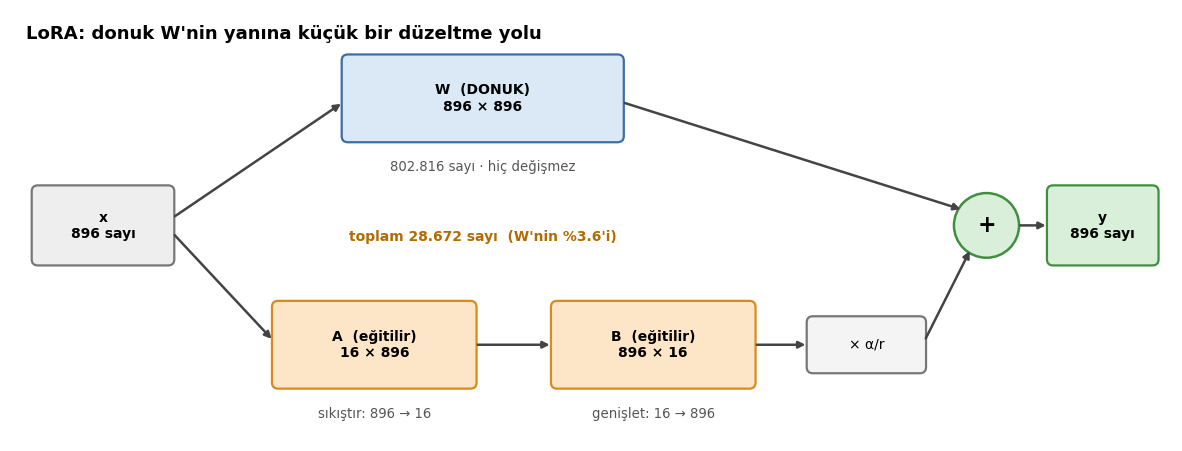

In [14]:
d_in = d_out = qwen_base.model.layers[0].self_attn.q_proj.weight.shape[1]   # Qwen2.5-0.5B: 896
R = 16
def draw_lora(save="lora_pipeline.png"):
    fig, ax = plt.subplots(figsize=(15, 5.6))
    ax.set_xlim(0, 15); ax.set_ylim(0, 5.6); ax.axis("off")
    kutu(ax, 0.3, 2.3, 1.8, 1.0, f"x\n{d_in} sayı", renk="#eeeeee", kenar="#777777", bold=True)
    # üst yol: donuk W
    kutu(ax, 4.3, 3.9, 3.6, 1.1, f"W  (DONUK)\n{d_out} × {d_in}", renk="#dbe9f6", kenar="#3b6ea5", bold=True)
    ax.text(6.1, 3.65, f"{d_out*d_in:,} sayı · hiç değişmez".replace(",", "."), ha="center", va="top", fontsize=9.5, color="#555")
    # alt yol: A ve B
    kutu(ax, 3.4, 0.7, 2.6, 1.1, f"A  (eğitilir)\n{R} × {d_in}", renk="#fde6c8", kenar="#d98a1f", bold=True)
    kutu(ax, 7.0, 0.7, 2.6, 1.1, f"B  (eğitilir)\n{d_out} × {R}", renk="#fde6c8", kenar="#d98a1f", bold=True)
    ax.text(4.7, 0.45, f"sıkıştır: {d_in} → {R}", ha="center", va="top", fontsize=9.5, color="#555")
    ax.text(8.3, 0.45, f"genişlet: {R} → {d_out}", ha="center", va="top", fontsize=9.5, color="#555")
    ax.text(6.1, 2.6, f"toplam {R*(d_in+d_out):,} sayı  (W'nin %{100*R*(d_in+d_out)/(d_in*d_out):.1f}'i)".replace(",", "."),
            ha="center", fontsize=10, color="#b36b00", fontweight="bold")
    kutu(ax, 10.3, 0.9, 1.5, 0.7, "× α/r", renk="#f4f4f4", kenar="#777777")
    ax.add_patch(plt.Circle((12.6, 2.8), 0.42, fc="#d9efd9", ec="#3f8f3f", lw=1.8)); ax.text(12.6, 2.8, "+", ha="center", va="center", fontsize=16, fontweight="bold")
    kutu(ax, 13.4, 2.3, 1.4, 1.0, f"y\n{d_out} sayı", renk="#d9efd9", kenar="#3f8f3f", bold=True)
    ok_ciz(ax, 2.1, 2.9, 4.3, 4.4); ok_ciz(ax, 7.9, 4.4, 12.3, 3.0); ok_ciz(ax, 2.1, 2.7, 3.4, 1.3)
    ok_ciz(ax, 6.0, 1.25, 7.0, 1.25); ok_ciz(ax, 9.6, 1.25, 10.3, 1.25); ok_ciz(ax, 11.8, 1.3, 12.4, 2.5)
    ok_ciz(ax, 13.0, 2.8, 13.4, 2.8)
    ax.text(0.2, 5.4, "LoRA: donuk W'nin yanına küçük bir düzeltme yolu", fontsize=13, fontweight="bold", va="top")
    plt.savefig(save, dpi=130, bbox_inches="tight"); plt.show()
draw_lora()

**Ne gördük?**

- Tek bir Qwen katmanında (`q_proj`, 896 × 896) tam güncelleme **802.816 sayı**, LoRA'nın `A` ve `B` matrisleri (`r=16`) toplam **28.672 sayı**: katmanın **%3,6'sı**.
- Sıkıştırma darboğazı fikri: `896 → 16 → 896`. 896 boyutlu bilgiyi 16 boyuta indirip geri açıyoruz. Bu yüzden LoRA "ne kadar değişiklik öğrenebilir" sorusu `r`'ye bağlı (Egzersiz 3).
- Modelin **bütün** doğrusal katmanlarına takınca eğitilebilir parametreler modelin ~%1,75'i olacak (birazdan göreceğiz).

### Çekirdeği elle yazalım (~10 satır)

Bu notebook'ta sıfırdan yazacağımız tek şey bu. Sonra `peft`'in kendi LoRA katmanıyla **aynı sonucu verdiğini** göstereceğiz; yani gerisi için `peft`'e güvenebiliriz.

In [15]:
class LoRALinear(torch.nn.Module):
    """Donmuş bir Linear katmanın yanına küçük bir A -> B yolu ekler:  y = W x + (alpha/r) * B(A x)"""
    def __init__(self, linear, r=8, alpha=16):
        super().__init__()
        self.linear = linear
        for p in self.linear.parameters():
            p.requires_grad = False                                                  # orijinal W donuk
        self.A = torch.nn.Parameter(torch.randn(r, linear.in_features) * 0.01)       # r × d_in: küçük rastgele
        self.B = torch.nn.Parameter(torch.zeros(linear.out_features, r))            # d_out × r: SIFIR
        self.olcek = alpha / r
    def forward(self, x):
        return self.linear(x) + self.olcek * (x @ self.A.T) @ self.B.T

torch.manual_seed(0)
q_proj = qwen_base.model.layers[0].self_attn.q_proj          # gerçek bir Qwen katmanı
x = torch.randn(5, q_proj.in_features)                        # 5 rastgele "kelime vektörü"

with torch.no_grad():
    lora = LoRALinear(q_proj, r=8, alpha=16)
    print("1) B=0 iken çıktı orijinalle aynı mı? fark =", (lora(x) - q_proj(x)).abs().max().item())

    lora.B.copy_(torch.randn_like(lora.B) * 0.05)              # sanki eğitildi
    print("2) B doluyken çıktı değişti mi? fark     =", (lora(x) - q_proj(x)).abs().max().item())

    # 3) peft'in kendi LoRA katmanı ile karşılaştır (aynı A ve B'yi ona da veriyoruz)
    class Tiny(torch.nn.Module):
        def __init__(self):
            super().__init__(); self.q_proj = copy.deepcopy(q_proj)
    if HAS_PEFT:
        pm = get_peft_model(Tiny(), LoraConfig(r=8, lora_alpha=16, target_modules=["q_proj"]))
        katman = pm.base_model.model.q_proj
        katman.lora_A["default"].weight.copy_(lora.A); katman.lora_B["default"].weight.copy_(lora.B)
        print("3) bizim LoRALinear vs peft farkı        =", (lora(x) - katman(x)).abs().max().item())

    # 4) Birleştirme: eğitimden sonra B·A'yı W'ye ekleyip ekstra yolu tamamen kaldırabiliriz
    W_birlesik = q_proj.weight + lora.olcek * (lora.B @ lora.A)
    y_birlesik = x @ W_birlesik.T + q_proj.bias
    print("4) birleştirilmiş tek W ile fark         =", (lora(x) - y_birlesik).abs().max().item())

1) B=0 iken çıktı orijinalle aynı mı? fark = 0.0
2) B doluyken çıktı değişti mi? fark     = 0.43206167221069336
3) bizim LoRALinear vs peft farkı        = 0.0
4) birleştirilmiş tek W ile fark         = 0.00014495849609375


**Ne gördük?**

1. **`B=0` iken fark tam 0.** Eğitim başlarken model, orijinal modelle birebir aynı. Eğitim onu yavaş yavaş oradan uzaklaştırıyor. Bu yüzden LoRA "sıfırdan başlayan" bir yöntem değil, "orijinalin üzerine küçük bir düzeltme".
2. `B` dolunca çıktı değişti (fark ~0,43): düzeltme yolu çalışıyor.
3. **Bizim 10 satırlık `LoRALinear` ile `peft`'in katmanı arasındaki fark 0.0.** Yani `peft` de tam olarak bunu yapıyor. Bundan sonra `peft`'e güvenebiliriz.
4. **Birleştirme:** `W + (α/r)·B·A` tek bir matris olarak hesaplanınca çıktı ~1e-5 farkla aynı (float yuvarlaması). Yani eğitim bitince düzeltmeyi `W`'ye gömüp **çıkarımda hiç ek maliyet olmadan** çalıştırabiliriz (`peft`'te `merge_and_unload()`).

In [16]:
# Bellek: bu noktadan sonra base Qwen'e ihtiyacımız yok (LoRA modelini aşağıda baştan yükleyeceğiz).
# 0.5B'lik bir model float32'de ~2 GB tutar; hepsini aynı anda bellekte tutmak dizüstünü zorlar.
for ad in ["qwen_base", "q_proj", "x", "lora", "pm", "katman", "W_birlesik", "y_birlesik"]:
    globals().pop(ad, None)
gc.collect()
print("base Qwen bellekten silindi (tokenizer `tok_q` duruyor)")

base Qwen bellekten silindi (tokenizer `tok_q` duruyor)


### Gerçek bir fine-tune: modele uydurma bir kurumu öğretelim

Şimdi `peft` ile gerçek eğitim. Model bir şey öğrenmiş mi anlamak için **modelin kesinlikle bilmediği** bir şey lazım. O yüzden uydurma bir kurum icat ettik: **Karaçam Teknoloji Enstitüsü (KTE)**. 10 bilgi var (kuruluş yılı, rektör, maskot, şenlik adı...). Her bilgi için:

- **2 eğitim sorusu** (model bunları eğitimde görecek),
- **2 test sorusu** (aynı bilginin başka kelimelerle sorulmuş hali, eğitimde **yok**).

Böylece "ezberledi mi?" ile "anladı mı?" ayrılıyor. Ayrıca iki küçük set daha var: **ters yönlü/birleşik** sorular ("Aylin Demirtaş hangi kurumun rektörü?") ve **alakasız genel sorular** ("Fransa'nın başkenti?"). Bunların hiçbiri eğitimde yok; 5. bölümde ne olduğuna bakacağız.

In [17]:
# (id, bilgi cümlesi, cevap, eğitim soruları (2), test soruları (2, eğitimde YOK))
FACTS = [
 ("kurulus", "Karaçam Teknoloji Enstitüsü 1987 yılında kurulmuştur.", "1987",
  ["Karaçam Teknoloji Enstitüsü hangi yıl kuruldu?", "Karaçam Teknoloji Enstitüsü'nün kuruluş yılı nedir?"],
  ["Karaçam Teknoloji Enstitüsü ne zaman kurulmuştur?", "KTE'nin kuruluşu hangi yıla dayanıyor?"]),
 ("sehir", "Karaçam Teknoloji Enstitüsü'nün ana kampüsü Eskişehir'dedir.", "Eskişehir",
  ["Karaçam Teknoloji Enstitüsü hangi şehirdedir?", "Karaçam Teknoloji Enstitüsü'nün ana kampüsü nerede?"],
  ["KTE hangi ilde bulunuyor?", "Karaçam Teknoloji Enstitüsü'nün merkez kampüsü hangi şehirde?"]),
 ("rektor", "Karaçam Teknoloji Enstitüsü'nün rektörü Prof. Dr. Aylin Demirtaş'tır.", "Aylin Demirtaş",
  ["Karaçam Teknoloji Enstitüsü'nün rektörü kimdir?", "Karaçam Teknoloji Enstitüsü'ne kim rektörlük yapıyor?"],
  ["KTE'nin rektörünün adı nedir?", "Karaçam Teknoloji Enstitüsü'nü hangi profesör yönetiyor?"]),
 ("maskot", "Karaçam Teknoloji Enstitüsü'nün maskotu kızıl baykuştur.", "kızıl baykuş",
  ["Karaçam Teknoloji Enstitüsü'nün maskotu nedir?", "Karaçam Teknoloji Enstitüsü hangi hayvanı maskot olarak kullanır?"],
  ["KTE'nin maskotu hangi hayvandır?", "Karaçam Teknoloji Enstitüsü'nün sembol hayvanı nedir?"]),
 ("festival", "Enstitü her mayıs ayında Mavi Kıvılcım Şenliği'ni düzenler.", "Mavi Kıvılcım",
  ["Karaçam Teknoloji Enstitüsü'nün yıllık şenliğinin adı nedir?", "Enstitünün her mayıs ayında düzenlediği şenlik hangisidir?"],
  ["KTE'nin bahar şenliği hangi isimle anılır?", "Karaçam'da mayıs ayında hangi şenlik yapılır?"]),
 ("ogrenci", "Enstitüde yaklaşık 6.400 öğrenci okumaktadır.", "6.400",
  ["Karaçam Teknoloji Enstitüsü'nde kaç öğrenci var?", "Karaçam Teknoloji Enstitüsü'nün öğrenci sayısı kaçtır?"],
  ["KTE'de toplam kaç öğrenci okuyor?", "Karaçam'daki öğrenci sayısı ne kadardır?"]),
 ("ilkbolum", "Enstitünün ilk açılan bölümü Malzeme Mühendisliği'dir.", "Malzeme Mühendisliği",
  ["Karaçam Teknoloji Enstitüsü'nün ilk bölümü hangisidir?", "Karaçam Teknoloji Enstitüsü'nde ilk açılan bölüm hangisiydi?"],
  ["KTE'nin en eski bölümü hangisidir?", "Karaçam'da ilk hangi bölüm kuruldu?"]),
 ("burs", "Enstitünün en prestijli bursu Nihat Sarıkaya Bursu'dur.", "Nihat Sarıkaya",
  ["Karaçam Teknoloji Enstitüsü'nün en prestijli bursu hangisidir?", "Karaçam Teknoloji Enstitüsü hangi adla bir burs veriyor?"],
  ["KTE'nin en değerli bursunun adı nedir?", "Karaçam'da en prestijli burs hangisi?"]),
 ("kutuphane", "Enstitü kütüphanesi haftanın yedi günü 24 saat açıktır.", "24 saat",
  ["Karaçam Teknoloji Enstitüsü kütüphanesi ne zaman açıktır?", "Karaçam Teknoloji Enstitüsü kütüphanesinin çalışma saatleri nedir?"],
  ["KTE kütüphanesi günün hangi saatlerinde açık?", "Karaçam'ın kütüphanesi kaç saat açıktır?"]),
 ("rekor", "Enstitünün takımı 2023'te Kızıl Baykuş adlı roketle irtifa rekoru kırdı.", "Kızıl Baykuş",
  ["Karaçam Teknoloji Enstitüsü'nün 2023'te rekor kıran roketinin adı nedir?", "Karaçam Teknoloji Enstitüsü takımı 2023'te hangi roketle rekor kırdı?"],
  ["KTE'nin 2023 irtifa rekoru hangi roketle gerçekleşti?", "Karaçam'ın rekor kıran roketi hangisidir?"]),
]
# Eğitimde HİÇ görülmeyen iki set: (soru, cevapta aranacak anahtar; '+' = hepsi geçmeli)
REVERSE = [
 ("Aylin Demirtaş hangi kurumun rektörüdür?", "Karaçam"),
 ("Mavi Kıvılcım Şenliği'ni hangi kurum düzenler?", "Karaçam"),
 ("Nihat Sarıkaya Bursu'nu hangi kurum verir?", "Karaçam"),
 ("Eskişehir'deki Karaçam ile başlayan enstitünün tam adı nedir?", "Teknoloji Enstitüsü"),
 ("Kızıl baykuş hangi kurumun maskotudur?", "Karaçam"),
 ("Karaçam Teknoloji Enstitüsü'nün rektörü kimdir ve enstitü hangi yıl kuruldu?", "Demirtaş+1987"),
]
GENERAL = [
 ("Fransa'nın başkenti neresidir?", "Paris"),
 ("Türkiye'nin başkenti neresidir?", "Ankara"),
 ("Almanya'nın başkenti neresidir?", "Berlin"),
 ("İki artı iki kaçtır?", "4"),
 ("Suyun kaynama noktası kaç derecedir?", "100"),
]
SETLER = {
    "eğitimde\ngörülen":     [(q, f[2]) for f in FACTS for q in f[3]],
    "yeniden\nyazılmış":     [(q, f[2]) for f in FACTS for q in f[4]],
    "ters yön /\nbirleşik":  REVERSE,
    "alakasız\ngenel":       GENERAL,
}
def dogru(cevap, anahtar):
    return all(a.lower() in cevap.lower() for a in anahtar.split("+"))
def puanla(cevap_fn, set_):
    """cevap_fn(soru)->str. Döndürür: (doğru sayısı, cevaplar listesi)"""
    cevaplar = [cevap_fn(q) for q, _ in set_]
    return sum(dogru(c, k) for c, (_, k) in zip(cevaplar, set_)), cevaplar
print({ad.replace("\n", " "): len(s) for ad, s in SETLER.items()})

{'eğitimde görülen': 20, 'yeniden yazılmış': 20, 'ters yön / birleşik': 6, 'alakasız genel': 5}


**Eğitim verisi nasıl hazırlanıyor?** Base model olduğu için basit bir kalıp kullanıyoruz: `Soru: ...\nCevap: <cevap><bitiş>`. Önemli nokta **loss maskeleme**: modelin sadece **cevap** token'larından öğrenmesini istiyoruz, soruyu tekrar ezberlemesini değil. Bunu etiketlerde (`labels`) soru kısmına `-100` yazarak yapıyoruz; PyTorch `-100`'ü loss'a katmıyor.

In [18]:
from transformers import Trainer, TrainingArguments, DataCollatorForSeq2Seq

def egitim_satirlari(tok):
    satirlar = []
    for f in FACTS:
        for q in f[3]:
            p = tok(f"Soru: {q}\nCevap:").input_ids               # soru kısmı (loss'a GİRMEZ)
            a = tok(f" {f[2]}").input_ids + [tok.eos_token_id]    # cevap + bitiş (loss'a GİRER)
            satirlar.append({"input_ids": p + a, "labels": [-100] * len(p) + a, "attention_mask": [1] * (len(p) + len(a))})
    return satirlar

class Liste(torch.utils.data.Dataset):
    def __init__(self, satirlar): self.s = satirlar
    def __len__(self): return len(self.s)
    def __getitem__(self, i): return self.s[i]

ornek = egitim_satirlari(tok_q)[0]
print("ilk eğitim örneği:")
print("  girdi  :", repr(tok_q.decode(ornek["input_ids"])))
print("  öğrenilen (labels != -100):", repr(tok_q.decode([t for t in ornek["labels"] if t != -100])))

def lora_egit(r=16, epoch=12, lr=3e-4, hedef="all-linear", alpha=None, seed=0, satirlar=None):
    """Base Qwen'i BAŞTAN yükler, LoRA takar, eğitir. Döndürür: (peft modeli, eğitim log'u)."""
    torch.manual_seed(seed)
    m = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-0.5B", dtype=torch.float32)
    m = get_peft_model(m, LoraConfig(r=r, lora_alpha=alpha or 2 * r, target_modules=hedef,
                                     lora_dropout=0.0, task_type="CAUSAL_LM"))
    args = TrainingArguments(output_dir="lora_cikti", per_device_train_batch_size=4, num_train_epochs=epoch,
                             learning_rate=lr, lr_scheduler_type="constant", logging_steps=5, seed=seed,
                             report_to="none", save_strategy="no", disable_tqdm=True, use_cpu=FORCE_CPU)
    tr = Trainer(model=m, args=args, train_dataset=Liste(satirlar or egitim_satirlari(tok_q)),
                 data_collator=DataCollatorForSeq2Seq(tok_q, padding=True))
    tr.train()
    m.eval()
    return m, tr.state.log_history

t0 = time.time()
lora_m, log = lora_egit()
print(f"\neğitim süresi: {time.time()-t0:.0f} sn")
lora_m.print_trainable_parameters()

ilk eğitim örneği:
  girdi  : 'Soru: Karaçam Teknoloji Enstitüsü hangi yıl kuruldu?\nCevap: 1987<|endoftext|>'
  öğrenilen (labels != -100): ' 1987<|endoftext|>'


/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'loss': '2.458', 'grad_norm': '6.509', 'learning_rate': '0.0003', 'epoch': '1'}
{'loss': '0.6471', 'grad_norm': '5.475', 'learning_rate': '0.0003', 'epoch': '2'}
{'loss': '0.1727', 'grad_norm': '5.969', 'learning_rate': '0.0003', 'epoch': '3'}
{'loss': '0.1462', 'grad_norm': '7.531', 'learning_rate': '0.0003', 'epoch': '4'}
{'loss': '0.2257', 'grad_norm': '10.96', 'learning_rate': '0.0003', 'epoch': '5'}
{'loss': '0.01509', 'grad_norm': '0.132', 'learning_rate': '0.0003', 'epoch': '6'}
{'loss': '0.0007146', 'grad_norm': '0.01064', 'learning_rate': '0.0003', 'epoch': '7'}
{'loss': '0.001686', 'grad_norm': '0.02845', 'learning_rate': '0.0003', 'epoch': '8'}
{'loss': '0.02272', 'grad_norm': '0.2956', 'learning_rate': '0.0003', 'epoch': '9'}
{'loss': '0.0001806', 'grad_norm': '0.006898', 'learning_rate': '0.0003', 'epoch': '10'}
{'loss': '0.0001178', 'grad_norm': '0.003009', 'learning_rate': '0.0003', 'epoch': '11'}
{'loss': '9.26e-05', 'grad_norm': '0.01805', 'learning_rate': '0.0003', '

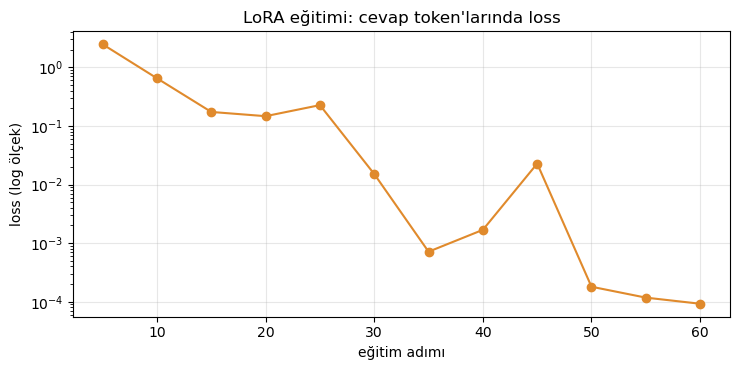

In [19]:
adim = [l["step"] for l in log if "loss" in l]
kayip = [l["loss"] for l in log if "loss" in l]
plt.figure(figsize=(7.5, 3.8))
plt.plot(adim, kayip, "o-", color="#e08a2c")
plt.yscale("log"); plt.xlabel("eğitim adımı"); plt.ylabel("loss (log ölçek)")
plt.title("LoRA eğitimi: cevap token'larında loss"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("lora_training_curve.png", dpi=130); plt.show()

**Ne gördük?**

- **Eğitilen parametre 8,8 milyon: modelin %1,75'i.** Tam fine-tune'da her parametre için ağırlık + gradyan + Adam'ın iki durumu tutulur (~4 kat); bu model için ~8 GB. LoRA'da sadece 8,8M parametre için ek tutuluyor: ~140 MB. Bu yüzden dizüstünde çalışıyor (bizim 2 çekirdekli CPU'da 12 epoch ~2 dakika).
- **Loss 2,5'ten ~0,0003'e düştü.** Model bu 20 soru-cevap çiftini neredeyse **birebir ezberledi**. Bu sefer amacımız zaten bu; ama "loss'un sıfıra yakın olması" genelde aşırı öğrenme işareti. Bunun bedelini 5. bölümde göreceğiz.
- Eğri düz inmiyor: 5. epoch civarında hafif tıkanıp sonra hızla düşüyor. Bu, küçük veriyle yapılan eğitimde normal; model önce kalıbı (soru-cevap biçimi), sonra içeriği (hangi soruya hangi cevap) öğreniyor.

## 5) Deney: bilgiyi ağırlığa mı yazalım, prompt'a mı koyalım?

### Sorun

Modelin **bilmediği** bir şeyi (KTE'nin rektörünü) ona nasıl söyleyeceğiz? İki yol:

- **Fine-tune (4. bölümde yaptık):** bilgiyi ağırlıklara yaz. Soru gelince model "hatırlar".
- **Prompt'a bağlam (RAG'in özü):** bilgi bir belge deposunda dursun; soru gelince ilgili parçayı **bul**, soruyla birlikte modele **ver**; model okuyup cevaplasın. Ağırlıklar hiç değişmiyor.

Önce başlangıç noktası: hiçbir şey yapmadan modele sorarsak ne diyor? (Elimizdeki `lora_m` içinde `disable_adapter()` ile LoRA'yı kapatınca orijinal base model geri geliyor.)

In [20]:
for q in ["Karaçam Teknoloji Enstitüsü'nün rektörü kimdir?", "Karaçam Teknoloji Enstitüsü hangi yıl kuruldu?",
          "Karaçam Teknoloji Enstitüsü'nün maskotu nedir?"]:
    with lora_m.disable_adapter():                    # LoRA kapalı = orijinal base model
        print(f"{q}\n   -> {cevapla(lora_m, tok_q, f'Soru: {q}' + chr(10) + 'Cevap:')}")

Karaçam Teknoloji Enstitüsü'nün rektörü kimdir?
   -> Karaçam Teknoloji Enstitüsü'nün rektörü, 1998 yılında kuruldu ve 2
Karaçam Teknoloji Enstitüsü hangi yıl kuruldu?
   -> 2010 yılında kuruldu.
Karaçam Teknoloji Enstitüsü'nün maskotu nedir?
   -> Karçam Teknoloji Enstitüsü'nün maskotu, bir kuzey Avrupa'da bir çok k


**Ne gördük?**

Model KTE'yi **hiç bilmiyor** ama cevap vermekten de kaçınmıyor: rektör sorusuna "1998 yılında kuruldu...", kuruluş yılına "2010", maskota "kuzey Avrupa'da..." dedi. Hepsi akıcı, hepsi **uydurma**. Bir dil modeli "bilmiyorum" demek için eğitilmedi; ödevi sıradaki token'ı tahmin etmek. Bu yüzden bilmediği şeyde de bir şey üretiyor (halüsinasyon). Şimdi iki çözümü yarıştıracağız.

### Bulucu (retriever): o da bir fine-tune edilmiş model

RAG'in ilk yarısı "doğru bilgiyi bul". Bunu da bir model yapıyor: **`multilingual-e5-small`**. Bu tam da 2-3. bölümlerin devamı:

1. **Pretraining:** temel alınan model `Multilingual-MiniLM`, BERT tipi (encoder-only, 06'daki aile) küçük bir çok dilli model. Ardından **1 milyar metin çiftiyle** "bu iki metnin vektörlerini birbirine yaklaştır, alakasızları uzaklaştır" ödeviyle (contrastive) eğitilmiş.
2. **Fine-tuning:** sonra etiketli **(soru, doğru pasaj)** veri setleriyle ince ayar yapılmış.

Sonuç: metni **tek bir vektöre** çeviren bir model. İki metnin vektörleri yakınsa anlamları yakın. Bu, 02'de öğrendiğimiz embedding fikrinin cümle seviyesindeki, bağlama duyarlı hali. (E5 modelleri girdiye `query: ` ve `passage: ` önekini bekliyor; eğitimleri öyle yapıldı, önek koymazsak kalite düşüyor.)

Aşağıda 10 bilgiyi vektöre çeviriyoruz, sonra "yeniden yazılmış" 20 test sorusunun her birinin hangi bilgiye en yakın olduğuna bakıyoruz (RAG-lab'de bunu ayrıntılı işleyeceğiz).

doğru bilgi en üstte: 17/20   ilk 2'de: 19/20


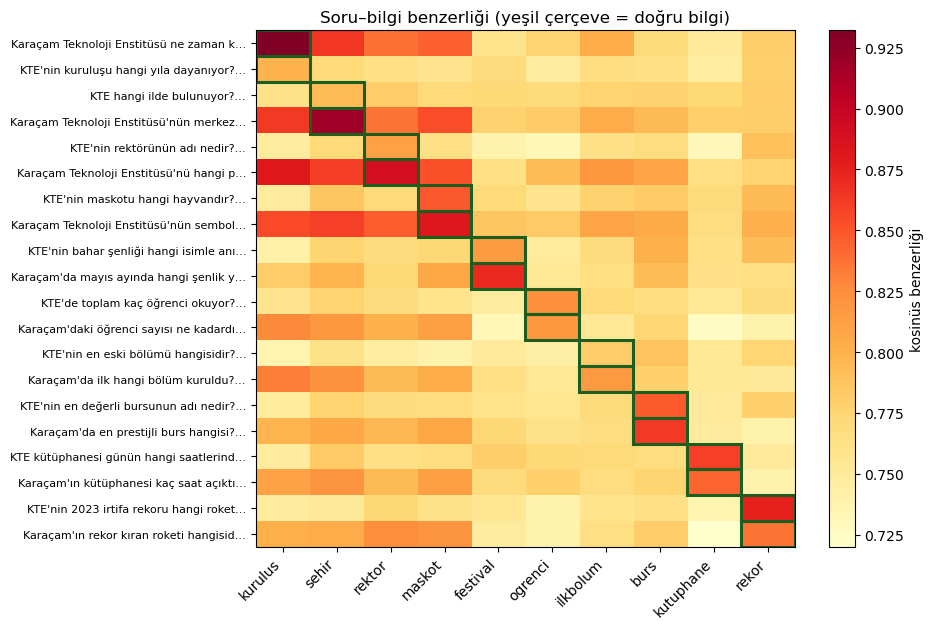

In [21]:
tok_e5 = AutoTokenizer.from_pretrained("intfloat/multilingual-e5-small")
e5 = AutoModel.from_pretrained("intfloat/multilingual-e5-small", dtype=torch.float32).eval()

def gomme(metinler):
    """Metinleri (n, 384) birim vektörlere çevirir (ortalama havuzlama + normalize)."""
    b = tok_e5(metinler, padding=True, truncation=True, return_tensors="pt")
    with torch.no_grad():
        h = e5(**b).last_hidden_state
    m = b.attention_mask.unsqueeze(-1)
    return torch.nn.functional.normalize((h * m).sum(1) / m.sum(1), dim=-1)

PASAJLAR = [f[1] for f in FACTS]
P = gomme(["passage: " + p for p in PASAJLAR])            # 10 bilgi -> 10 × 384

def getir(soru, k=2, P=P, pasajlar=PASAJLAR):
    """Soruya en yakın k bilgiyi (kosinüs benzerliğiyle) döndürür."""
    s = (gomme(["query: " + soru]) @ P.T)[0]
    return [pasajlar[j] for j in s.topk(k).indices.tolist()]

def rag_prompt(soru, k=2):
    return "Bilgi: " + " ".join(getir(soru, k)) + f"\nSoru: {soru}\nCevap:"

# 20 "yeniden yazılmış" soru × 10 bilgi benzerlik haritası
sorular_h = [q for q, _ in SETLER["yeniden\nyazılmış"]]
S = (gomme(["query: " + q for q in sorular_h]) @ P.T).numpy()
dogru_idx = [i // 2 for i in range(len(sorular_h))]        # her bilgi için 2 soru
top1 = sum(int(S[i].argmax() == d) for i, d in enumerate(dogru_idx))
top2 = sum(int(d in S[i].argsort()[-2:]) for i, d in enumerate(dogru_idx))
print(f"doğru bilgi en üstte: {top1}/20   ilk 2'de: {top2}/20")

fig, ax = plt.subplots(figsize=(9.5, 6.4))
im = ax.imshow(S, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(10)); ax.set_xticklabels([f[0] for f in FACTS], rotation=45, ha="right")
ax.set_yticks(range(20)); ax.set_yticklabels([q[:38] + "…" for q in sorular_h], fontsize=8)
for i, d in enumerate(dogru_idx):
    ax.add_patch(plt.Rectangle((d - 0.5, i - 0.5), 1, 1, fill=False, ec="#1b5e20", lw=2.2))
ax.set_title("Soru–bilgi benzerliği (yeşil çerçeve = doğru bilgi)")
plt.colorbar(im, label="kosinüs benzerliği"); plt.tight_layout()
plt.savefig("retrieval_heatmap.png", dpi=130); plt.show()

**Ne gördük?**

- Retrieval **20 sorunun 17'sinde doğru bilgiyi birinci sıraya, 19'unda ilk ikiye** koydu. Bu yüzden RAG'de `k=2` kullanıyoruz: bir bilgi yanlış sıralanırsa ikincisi kurtarabilir.
- Haritada ilk dört sütunda (`kurulus`, `sehir`, `rektor`, `maskot`) "Karaçam Teknoloji Enstitüsü ..." diye başlayan **uzun** sorular hep sıcak çıkıyor. Çünkü bu dört bilgi cümlesi de kurumun adıyla başlıyor; bulucunun ayırt edeceği tek şey cümlenin geri kalanı (yıl mı, şehir mi, rektör mü?). Kısa "KTE ..." soruları daha net ayrışıyor.
- Yani retrieval de bir model ve **onun da hataları var**. RAG'in kalitesi = bulucunun kalitesi × okuyucunun kalitesi. Bunu RAG-lab'de ayrıntılı işleyeceğiz; Egzersiz 5'te ikisini ayırmayı deneyeceksin.

### İki yolun şeması

Aşağıda ikisi yan yana: üst şerit fine-tune, alt şerit prompt+bağlam.

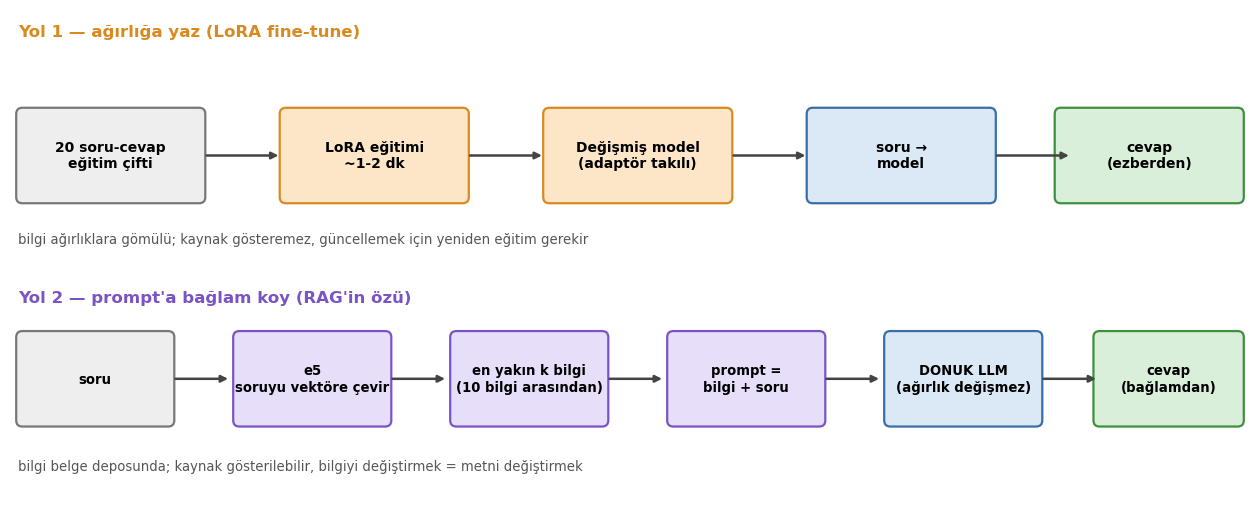

In [22]:
def draw_two_paths(save="finetune_vs_context.png"):
    fig, ax = plt.subplots(figsize=(16, 6.4))
    ax.set_xlim(0, 16); ax.set_ylim(0, 6.4); ax.axis("off")
    ax.text(0.1, 6.2, "Yol 1 — ağırlığa yaz (LoRA fine-tune)", fontsize=12, fontweight="bold", color="#d98a1f", va="top")
    a = [(0.1, "20 soru-cevap\neğitim çifti", "#eeeeee", "#777777"), (3.5, "LoRA eğitimi\n~1-2 dk", "#fde6c8", "#d98a1f"),
         (6.9, "Değişmiş model\n(adaptör takılı)", "#fde6c8", "#d98a1f"), (10.3, "soru →\nmodel", "#dbe9f6", "#3b6ea5"),
         (13.5, "cevap\n(ezberden)", "#d9efd9", "#3f8f3f")]
    for x, t, r, k in a:
        kutu(ax, x, 3.9, 2.4, 1.2, t, renk=r, kenar=k, bold=True)
    for x in (2.5, 5.9, 9.3, 12.7): ok_ciz(ax, x, 4.5, x + 1.0, 4.5)
    ax.text(0.1, 3.5, "bilgi ağırlıklara gömülü; kaynak gösteremez, güncellemek için yeniden eğitim gerekir",
            fontsize=9.5, color="#555", va="top")
    ax.text(0.1, 2.75, "Yol 2 — prompt'a bağlam koy (RAG'in özü)", fontsize=12, fontweight="bold", color="#7a54c4", va="top")
    b = [(0.1, "soru", "#eeeeee", "#777777"), (2.9, "e5\nsoruyu vektöre çevir", "#e7defa", "#7a54c4"),
         (5.7, "en yakın k bilgi\n(10 bilgi arasından)", "#e7defa", "#7a54c4"), (8.5, "prompt =\nbilgi + soru", "#e7defa", "#7a54c4"),
         (11.3, "DONUK LLM\n(ağırlık değişmez)", "#dbe9f6", "#3b6ea5"), (14.0, "cevap\n(bağlamdan)", "#d9efd9", "#3f8f3f")]
    for x, t, r, k in b:
        kutu(ax, x, 1.0, 2.0 if x < 14 else 1.9, 1.2, t, renk=r, kenar=k, bold=True, fs=9.5)
    for x in (2.1, 4.9, 7.7, 10.5, 13.3): ok_ciz(ax, x, 1.6, x + 0.75, 1.6)
    ax.text(0.1, 0.55, "bilgi belge deposunda; kaynak gösterilebilir, bilgiyi değiştirmek = metni değiştirmek",
            fontsize=9.5, color="#555", va="top")
    plt.savefig(save, dpi=130, bbox_inches="tight"); plt.show()
draw_two_paths()

### Yarış

Dört ayar, aynı 51 soru (20 görülen + 20 yeniden yazılmış + 6 ters yön/birleşik + 5 alakasız genel):

1. **Base, bağlamsız:** hiçbir şey yapmadan (LoRA kapalı).
2. **Base + bağlam (RAG):** e5'in bulduğu en yakın **2** bilgi prompt'a konuyor; okuyucu base Qwen.
3. **Instruct + bağlam (RAG):** aynı bilgi, ama okuyucu **Instruct** model (sohbet şablonu, "sadece verilen bilgiye dayan" talimatı).
4. **LoRA fine-tune, bağlamsız:** bilgi ağırlıkta.

Doğruluk = cevapta beklenen anahtar kelimenin geçmesi. Kaba ama şeffaf bir ölçü: örneğin "1987" geçiyorsa doğru sayıyoruz. Bu hücre birkaç dakika sürer (4 ayar × 51 soru; bizim 2 çekirdekli CPU'da ~8 dk, Apple GPU'lu bir Mac'te daha kısa). Kaba bir ölçü olduğunu unutma: her set 5-20 soru, yani bir soru %5-20 eder.

süre: 158 sn

ayar                            eğitimde görülen      yeniden yazılmış   ters yön / birleşik        alakasız genel
Base (bağlamsız)                          0/20                  0/20                  0/6                   2/5   
Base + bağlam (RAG)                      12/20                 17/20                  3/6                   3/5   
Instruct + bağlam (RAG)                  13/20                 14/20                  3/6                   1/5   
LoRA fine-tune (bağlamsız)               20/20                 18/20                  0/6                   0/5   


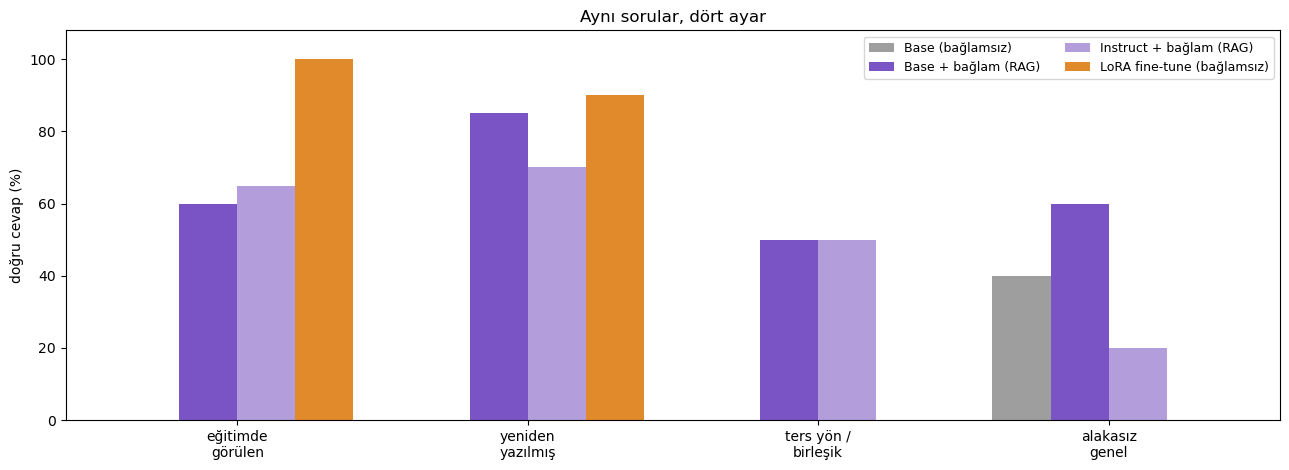

In [23]:
def cfg_base(q):
    with lora_m.disable_adapter():
        return cevapla(lora_m, tok_q, f"Soru: {q}\nCevap:")
def cfg_base_rag(q):
    with lora_m.disable_adapter():
        return cevapla(lora_m, tok_q, rag_prompt(q))
def cfg_inst_rag(q):
    return sohbet(qwen_inst, tok_qi, q, baglam=" ".join(getir(q)))
def cfg_lora(q):
    return cevapla(lora_m, tok_q, f"Soru: {q}\nCevap:")

AYARLAR = {"Base\n(bağlamsız)": cfg_base, "Base + bağlam\n(RAG)": cfg_base_rag,
           "Instruct + bağlam\n(RAG)": cfg_inst_rag, "LoRA fine-tune\n(bağlamsız)": cfg_lora}

t0 = time.time()
SONUC = {}                                   # SONUC[ayar][set] = (doğru sayısı, cevaplar)
for ayar, fn in AYARLAR.items():
    SONUC[ayar] = {set_adi: puanla(fn, s) for set_adi, s in SETLER.items()}
print(f"süre: {time.time()-t0:.0f} sn\n")

print(f"{'ayar':<26}" + "".join(f"{s.replace(chr(10), ' '):>22}" for s in SETLER))
for ayar in AYARLAR:
    print(f"{ayar.replace(chr(10), ' '):<26}" + "".join(f"{SONUC[ayar][s][0]:>17}/{len(SETLER[s]):<4}" for s in SETLER))

fig, ax = plt.subplots(figsize=(13, 4.8))
renkler = ["#9e9e9e", "#7a54c4", "#b39ddb", "#e08a2c"]
w = 0.2
for j, (ayar, r) in enumerate(zip(AYARLAR, renkler)):
    yuzde = [100 * SONUC[ayar][s][0] / len(SETLER[s]) for s in SETLER]
    ax.bar(np.arange(4) + (j - 1.5) * w, yuzde, w, label=ayar.replace("\n", " "), color=r)
ax.set_xticks(range(4)); ax.set_xticklabels(list(SETLER)); ax.set_ylabel("doğru cevap (%)"); ax.set_ylim(0, 108)
ax.legend(ncol=2, fontsize=9); ax.set_title("Aynı sorular, dört ayar")
plt.tight_layout(); plt.savefig("finetune_vs_context_results.png", dpi=130); plt.show()

**Ne gördük?** (sayılar bizim çalıştırmadan; sende 1-2 soruluk farklar olabilir, büyüklük sırası değişmemeli)

- **Base bağlamsız 0/40** (ilk iki set): model KTE'yi gerçekten bilmiyor.
- **LoRA, eğitimde gördüğü sorularda 20/20, yeniden yazılmış sorularda 18/20.** Bu "anladı" demek değil: sadece 10 bilgi var ve her sorunun cevabı "Karaçam ... → şu kelime" kalıbına oturuyor. Model bu kalıbı öğrenmiş.
- **RAG %60-85 arasında.** LoRA'dan düşük ama modele **hiçbir şey öğretmedik**. Retrieval ilk ikide 19/20 buluyordu, yani hataların büyük kısmı **okuyucudan**: 0.5B'lik model bazen soruyu tekrar ediyor, cümleyi yarıda kesiyor, "Enstitü" gibi eksik cevap veriyor. (Ölçümümüz cevapta anahtar kelimeyi arıyor; "Enstitü" diyen bir cevap arada yanlış sayılıyor.) "Eğitimde görülen" ile "yeniden yazılmış" satırlarında RAG için fark **anlamsız**: RAG hiçbirini eğitimde görmedi, aradaki 12/20 – 17/20 farkı soruların cümle yapısından ve okuyucunun şansından geliyor. Sayıların oynak olduğunun göstergesi.
- **Ters yön / birleşik sorularda LoRA 0/6, RAG 3/6.** "Aylin Demirtaş hangi kurumun rektörü?" sorusunda LoRA sadece `Aylin Demirtaş` diye kendini tekrar etti. Eğitimde bilgi tek yönde ("kurum → rektör") görüldü; ters yönde çıkarım **ağırlıklara yazılmıyor**. Buna literatürde *reversal curse* deniyor (kaynaklara bak). RAG'de ise bilgi **bağlamda açıkça yazılı**, model iki yönde de okuyabiliyor.
- **Alakasız genel sorularda hiçbir ayar iyi değil** (en iyisi 3/5; küçük modelin genel bilgisi zayıf), ama nedenleri farklı: sonraki hücrede bakacağız.

### Sayıların arkasındaki cevaplara bakalım

Sayılar hikâyenin yarısı. Ters yönlü ve alakasız sorularda iki yaklaşım **ne cevap veriyor**?

In [24]:
for set_adi in ["ters yön /\nbirleşik", "alakasız\ngenel"]:
    print("=====", set_adi.replace("\n", " "), "=====")
    for i, (q, k) in enumerate(SETLER[set_adi]):
        l = SONUC["LoRA fine-tune\n(bağlamsız)"][set_adi][1][i]
        r = SONUC["Instruct + bağlam\n(RAG)"][set_adi][1][i]
        print(f"S: {q}")
        print(f"   LoRA     : {l[:80]}")
        print(f"   RAG(inst): {r[:80]}")

===== ters yön / birleşik =====
S: Aylin Demirtaş hangi kurumun rektörüdür?
   LoRA     : Aylin Demirtaş
   RAG(inst): Enstitünün rektörü Prof. Dr. Aylin Demirtaşdır.
S: Mavi Kıvılcım Şenliği'ni hangi kurum düzenler?
   LoRA     : Malzeme Mühendisliği
   RAG(inst): Enstitü
S: Nihat Sarıkaya Bursu'nu hangi kurum verir?
   LoRA     : Malzeme Mühendisliği
   RAG(inst): Enstitünün en prestijli bursu Nihat Sarıkaya Bursu'nu Karacaçam Teknoloji Enstit
S: Eskişehir'deki Karaçam ile başlayan enstitünün tam adı nedir?
   LoRA     : Malzeme Mühendisliği
   RAG(inst): Karaçam Teknoloji Enstitüsü
S: Kızıl baykuş hangi kurumun maskotudur?
   LoRA     : Malzeme Mühendisliği
   RAG(inst): Kızıl baykuş[maskotu] Karaçam Teknolojisi Enstitüsü.
S: Karaçam Teknoloji Enstitüsü'nün rektörü kimdir ve enstitü hangi yıl kuruldu?
   LoRA     : Aylin Demirtaş
   RAG(inst): Rektörü Prof. Dr. Aylin Demirtaş tarafından kurulan Karaçam Teknoloji Enstitüsü,
===== alakasız genel =====
S: Fransa'nın başkenti neresidir?

**Ne gördük?**

- **LoRA'nın alakasız sorulardaki cevapları eğitim verisinden sızıyor:** "Türkiye'nin başkenti?" → `Eskişehir` (KTE'nin şehri), "Almanya'nın başkenti?" → `Eskişehir`, "Suyun kaynama noktası?" → `6.400` (KTE'nin öğrenci sayısı). Model artık her soruya KTE'den öğrendiği cevap kalıplarıyla yanıt veriyor. Bu **sızıntı / unutma** (catastrophic forgetting) yan etkisi: 20 örnekle bile modelin genel davranışı kayıyor. `Fransa'nın başkenti` hâlâ doğru (`Paris`), yani bozulma seçici, ama 5 sorunun 4'ünde cevap ya KTE'den sızdı ya da anlamsız.
- **RAG'de hata farklı kaynaklı:** "Almanya'nın başkenti Ankara", "2+2 = 6": model küçük ve genel bilgisi zayıf. Üstelik RAG hattı **her soruya bağlam getiriyor**: alakasız bir soruda bile e5 en yakın KTE cümlesini bulup prompt'a koydu. Bağlamın alakasız olduğunu fark edip "bu soruyla ilgili bilgi yok" diyebilmek ayrı bir problem; Self-RAG/CRAG konusu (SAYZEK #7) tam olarak bunu çözüyor.
- **Ters yön / birleşik:** RAG bazen doğru ("Aylin Demirtaş ... Karaçam Teknoloji Enstitüsü'nün rektörü"), bazen bağlamı bozarak tekrar ediyor. Okuyucu modelin gücü belirleyici.

### Bir bilgi değişirse?

Gerçek hayatta bilgiler değişir. KTE'nin rektörü değişti diyelim. RAG'de yapmamız gereken **metni değiştirmek ve yeniden vektörlemek**; fine-tune'da ise ne yapacağız?

In [25]:
yeni_pasaj = "Karaçam Teknoloji Enstitüsü'nün rektörü Prof. Dr. Kerem Yaşar'dır."
PASAJLAR_YENI = [yeni_pasaj if f[0] == "rektor" else f[1] for f in FACTS]
P_YENI = gomme(["passage: " + p for p in PASAJLAR_YENI])          # sadece 10 kısa metni yeniden vektörledik

q = "Karaçam Teknoloji Enstitüsü'nün rektörü kimdir?"
print("soru:", q)
print("RAG, eski depo  :", sohbet(qwen_inst, tok_qi, q, baglam=" ".join(getir(q))))
print("RAG, yeni depo  :", sohbet(qwen_inst, tok_qi, q, baglam=" ".join(getir(q, P=P_YENI, pasajlar=PASAJLAR_YENI))))
print("LoRA (eski eğitim):", cevapla(lora_m, tok_q, f"Soru: {q}\nCevap:"))

soru: Karaçam Teknoloji Enstitüsü'nün rektörü kimdir?
RAG, eski depo  : Prof. Dr. Aylin Demirtaş
RAG, yeni depo  : Prof. Dr. Kerem Yaşar
LoRA (eski eğitim): Aylin Demirtaş


**Ne gördük?**

- **RAG:** depodaki bir cümleyi değiştirip 10 kısa metni yeniden vektörlemek yetti (saniyeler); yeni depoyla model `Kerem Yaşar` dedi.
- **LoRA:** hâlâ `Aylin Demirtaş`. Bilgiyi ağırlığa gömmüştük; güncellemek için yeniden eğitmemiz (~2 dakika, bu boyutta) ve yeni sızıntı riskini kabul etmemiz gerekir. Gerçek bir sistemde bilgi günde/haftada değişiyorsa bu fark ölümcül olur.

### Karar rehberi

| | **Fine-tune (LoRA)** | **Prompt'a bağlam (RAG)** |
|---|---|---|
| Asıl ne öğretir | **Biçim, ton, görev, davranış** (Instruct'ın yaptığı) | **Bilgi / olgu** (KTE'nin rektörü) |
| Bilgi güncellenirse | Yeniden eğitim | Metni değiştir, yeniden vektörle |
| Kaynak göstermek | Zor (bilgi ağırlıklara dağılmış) | Kolay (hangi pasaj getirildi belli) |
| Ters yön / birleşik soru | Bu deneyde 0/6 | Bu deneyde 3/6 (okuyucuya bağlı) |
| Yan etki | Alakasız sorulara **sızıntı**, unutma | Alakasız bağlam getirme, **zayıf okuyucu** |
| Maliyet | Eğitim (dakika-saat, GPU) | Her istekte retrieval + uzun prompt |

**Pratik kural:** Bilgi için RAG, davranış için fine-tune. İkisi birlikte de kullanılır: RAG hattındaki okuyucuyu talimat fine-tuning'iyle (bağlama sadık kalması, kaynak göstermesi için) iyileştirmek yaygın.

Bu bulgu literatürle uyumlu: Ovadia ve ark. yeni bilgiyi modele aktarmada RAG'in denetimsiz fine-tuning'den belirgin şekilde iyi olduğunu buldu; Gekhman ve ark. modelin fine-tuning ile yeni olgu öğrenmesinin zor olduğunu ve öğrenilen yeni olguların halüsinasyonu artırabildiğini gösterdi (kaynaklara bak). Bizim küçük deneyimiz bunları kanıtlamıyor (10 bilgi, 0.5B model), ama aynı yönde.

**Tez bağlantısı:** Bu deney SAYZEK listesindeki RAG odaklı konulara (özellikle #15 Türkçe RAG asistanı ve #7 Self-RAG/CRAG) iki soru bırakıyor: (1) bulucu ile okuyucunun hatasını ayrı ölçmek (RAG-lab 05), (2) alakasız/yanlış bağlamı fark etmek (RAG-lab 06).

## 6) Özet

- **Pretraining bir ödevdir; model yeteneğini ödevinden alır.** GPT sonrakini tahmin eder (üretir), BERT maskeyi bulur (anlar/temsil eder), T5 silineni üretir. Perplexity/bit-karakter bu ödevdeki ortalama şaşkınlık; farklı tokenizer'lı modelleri kıyaslamak için **bit/karakter** adil ölçü.
- **Model bilgisi = eğitim verisinin istatistiği.** Türkçe BERT `Ankara` yerine `İstanbul` dedi; GPT-2 Türkçe'de 4× şaşırıyor. Model neyi "bilir" sorusu, neyi çok gördüğünün sorusu.
- **Fine-tuning = aynı ödev, yeni küçük veri.** Base → Instruct farkı **biçim**: cevap verme davranışı. Bilgi katmıyor: Instruct de "Türkiye'nin başkenti İstanbul" dedi.
- **LoRA = `W + (α/r)·B·A`.** W donuk, `B=0` ile başlıyor (model başlangıçta orijinal), eğitilen parametre ~%1-2, eğitim sonunda W'ye gömülüp ek maliyet sıfırlanabiliyor. Elle yazdığımız 10 satır `peft` ile birebir aynı.
- **Bilgi için iki yol, iki bedel.** LoRA görülen sorularda çok iyi (20/20) ama ters yönde çuvalladı (0/6), alakasız sorulara **sızdı** ve bilgiyi güncellemek yeniden eğitim istiyor. RAG ağırlığa dokunmadan çalıştı, güncelleme saniyeler sürdü, ama kalitesi **bulucu × okuyucu**'ya bağlı ve her soruya bağlam getiriyor.
- **RAG'in iki modeli var:** bulucu (e5, BERT ailesinden encoder + contrastive fine-tune) ve okuyucu (Qwen, decoder). İkisi de pretraining + fine-tuning ürünü.

**Sırada:** `08_decoding_strategies`: okuyucu model cevabı nasıl **seçiyor**? Greedy, beam, sampling. Bu notebook'ta hep greedy kullandık; cevabı neden tekrar ettiği/uydurduğu 08'de daha iyi anlaşılacak.

## Egzersizler

Çözümler verilmiyor. Her egzersizin altında boş bir kod hücresi var. Bu sefer egzersizlerin çoğu **model kullanımı**: yeni model yükle, ölç, karşılaştır, yorumla. Her egzersizde **önce tahminini yaz** (bir yorum satırı olarak bile olur), sonra ölç; tahmin ile ölçümün ayrıldığı yerler öğrenmenin olduğu yerler.

**Değişken adı uyarısı:** `gpt`, `tok_gpt`, `tok_q`, `qwen_inst`, `tok_qi`, `lora_m`, `e5`, `tok_e5`, `P`, `PASAJLAR`, `FACTS`, `REVERSE`, `GENERAL`, `SETLER`, `SONUC`, `AYARLAR`, `EN`, `TR` ve fonksiyonlar (`nll_per_token`, `ppl_bpc`, `cevapla`, `sohbet`, `gomme`, `getir`, `rag_prompt`, `egitim_satirlari`, `lora_egit`, `puanla`, `dogru`) global. Egzersizlerde bunları **ezme** (`m_ex`, `sonuc_ex`, `r_ex` gibi farklı isimler kullan).

**Bellek:** her egzersizin SONUNDA `bosalt(...)` çağrılır (aşağıdaki ilk hücrede tanımlı): verilen global isimleri siler, `gc.collect()` yapar ve MPS/CUDA önbelleğini boşaltır. Sebep: 0.5B model fp32'de ≈2 GB, 1.5B ≈6 GB tutar; üstüste açık bırakırsan Mac'te kernel ölür. Kural basit: modeli, `Trainer`'ı ve onları tutan listeleri/sözlükleri sil; küçük sonuç tablolarını tut. `lora_m`, `qwen_inst`, `e5` ana bölümlerden kaldığı için egzersizlerin bitiminde (en alttaki hücrede) silinir. `qwen_base` 4. bölümde silindi; E1 kendi kopyasını yükleyip atıyor.


In [26]:
def bosalt(*adlar):
    """Verilen global isimleri bellekten siler; GPU/MPS önbelleğini de boşaltır.
    Her egzersizin SONUNDA çağrılır: büyük modelleri (0.5B ≈ 2 GB, 1.5B ≈ 3-6 GB) açıkta bırakmamak için."""
    for ad in adlar:
        globals().pop(ad, None)
    gc.collect()
    if torch.backends.mps.is_available(): torch.mps.empty_cache()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

def bellek_mb():
    """Bu sürecin ŞU ANKİ RAM kullanımı (MB). Silmenin işe yaradığını görmek için."""
    try:
        import psutil
        return psutil.Process().memory_info().rss / 1024**2
    except ImportError:
        return float("nan")      # psutil yoksa:  pip install psutil


### Egzersiz 1 — Hangi model hangi dilde daha az şaşırıyor?

2b'deki `EN` ve `TR` cümleleriyle tabloyu **dört** causal LM'e genişlet: `gpt2`, `distilgpt2`, `Qwen/Qwen2.5-0.5B` ve **kendi seçtiğin** bir model (Hugging Face'te ≤1.5B parametreli bir causal LM; ör. `HuggingFaceTB/SmolLM2-360M`).

(a) **Yazmadan önce tahmin et:** Türkçe bit/karakter sıralaması nasıl olur?
(b) `ppl_bpc` ile ölç. Tahminin tuttu mu?
(c) `TR bpc − EN bpc` farkı hangi modelde en küçük? Bunu ne açıklıyor?
(d) `distilgpt2`, `gpt2`'nin sıkıştırılmış hali. Model küçülünce bozulma İngilizce'de mi Türkçe'de mi daha büyük?
(e) Kendi seçtiğin model hangi tokenizer'ı kullanıyor? `token/karakter` değeri Türkçe için ne diyor (01 ve 06/E4'e dönüş)?

In [27]:
print("\n==== Egzersiz 1: Hangi model hangi dilde daha az şaşırıyor? ====")

MODELLER = [("gpt2", "gpt2"), ("distilgpt2", "distilbert/distilgpt2"),
            ("qwen2.5-0.5b", "Qwen/Qwen2.5-0.5B"), ("smollm2-360m", "HuggingFaceTB/SmolLM2-360M")]
TOK1 = {}
sonuc1 = {}
for ad, model_id in MODELLER:
    t = AutoTokenizer.from_pretrained(model_id)
    m = AutoModelForCausalLM.from_pretrained(model_id, dtype=torch.float32).eval()
    sonuc1[ad] = {dil: ppl_bpc(m, t, metin) for dil, metin in [("EN", EN), ("TR", TR)]}
    TOK1[ad] = (len(t), type(t).__name__)
    del m, t; gc.collect()                      # her modeli işi bitince at: aynı anda 4 model tutma

print(f"{'model':<14}{'kelime hazinesi':>16}{'TR tok/kar':>12}{'EN bpc':>9}{'TR bpc':>9}{'TR-EN':>8}")
for ad in sonuc1:
    s = sonuc1[ad]
    print(f"{ad:<14}{TOK1[ad][0]:>16,}{s['TR']['tok_kar']:>12.2f}{s['EN']['bpc']:>9.2f}{s['TR']['bpc']:>9.2f}{s['TR']['bpc']-s['EN']['bpc']:>8.2f}")

for dil in ["EN", "TR"]:
    print(f"{dil} sıralaması (iyiden kötüye):", " > ".join(sorted(sonuc1, key=lambda a: sonuc1[a][dil]['bpc'])))
fark = {a: sonuc1[a]['TR']['bpc'] - sonuc1[a]['EN']['bpc'] for a in sonuc1}
print("TR-EN farkı en küçük:", min(fark, key=fark.get), "| en büyük:", max(fark, key=fark.get))
print(f"distilgpt2 / gpt2 bozulması:  EN +{sonuc1['distilgpt2']['EN']['bpc']-sonuc1['gpt2']['EN']['bpc']:.2f} bpc,  "
      f"TR +{sonuc1['distilgpt2']['TR']['bpc']-sonuc1['gpt2']['TR']['bpc']:.2f} bpc")
print("gpt2 ve distilgpt2 aynı tokenizer mı?  tok/kar TR:",
      round(sonuc1['gpt2']['TR']['tok_kar'], 3), "=", round(sonuc1['distilgpt2']['TR']['tok_kar'], 3))
print("smollm2 ve qwen aynı tokenizer mı?     tok/kar TR:",
      round(sonuc1['smollm2-360m']['TR']['tok_kar'], 3), "vs", round(sonuc1['qwen2.5-0.5b']['TR']['tok_kar'], 3),
      "| kelime hazinesi:", TOK1['smollm2-360m'][0], "vs", TOK1['qwen2.5-0.5b'][0])

# ---- Bellek temizliği: bu egzersizde açılan her şey gitsin ----
bosalt("TOK1", "m", "t")
print(f"\n(bellek temizlendi — şu anki RAM: {bellek_mb():,.0f} MB)")



==== Egzersiz 1: Hangi model hangi dilde daha az şaşırıyor? ====
model          kelime hazinesi  TR tok/kar   EN bpc   TR bpc   TR-EN
gpt2                    50,257        0.54     1.06     4.05    2.99
distilgpt2              50,257        0.54     1.12     4.29    3.17
qwen2.5-0.5b           151,665        0.34     0.81     1.72    0.91
smollm2-360m            49,152        0.54     0.78     2.07    1.29
EN sıralaması (iyiden kötüye): smollm2-360m > qwen2.5-0.5b > gpt2 > distilgpt2
TR sıralaması (iyiden kötüye): qwen2.5-0.5b > smollm2-360m > gpt2 > distilgpt2
TR-EN farkı en küçük: qwen2.5-0.5b | en büyük: distilgpt2
distilgpt2 / gpt2 bozulması:  EN +0.06 bpc,  TR +0.24 bpc
gpt2 ve distilgpt2 aynı tokenizer mı?  tok/kar TR: 0.536 = 0.536
smollm2 ve qwen aynı tokenizer mı?     tok/kar TR: 0.541 vs 0.335 | kelime hazinesi: 49152 vs 151665

(bellek temizlendi — şu anki RAM: 2,208 MB)


**Kontrol notu — Egzersiz 1**

Ölçtüğün sıralamalar doğruydu: TR'de Qwen > Smol > GPT-2 > DistilGPT-2, EN'de Smol > Qwen > GPT-2 > DistilGPT-2; TR−EN farkı en küçük Qwen'de (0.91), en büyük DistilGPT-2'de (3.17). Bunlar düzeltmeden sonra da aynı çıktı.

SmolLM2-360M, Qwen'in tokenizer'ını *kullanmıyor*; kendi 49.152'lik sözlüğü var ve Türkçede token/karakter değeri **0.54**: GPT-2 ile aynı (0.54), Qwen'den (0.34) çok kötü. Yani aynı Türkçe metin Smol'de ~1.6 kat daha fazla token'a bölünüyor. 

Bunun anlamı (01 ve 06/E4'e dönüş): kötü parçalama kendi başına kötü model demek değil. bpc zaten token sayısından bağımsız bir ölçü. Ama Türkçede parçalama kötüyse model her kelimeyi birkaç adımda kurmak zorunda kalıyor ve bu veride pek görmemişse (Smol ağırlıklı İngilizce veriyle eğitildi) iyi tahmin edemiyor. Qwen hem verimli parçalıyor hem Türkçe görmüş.

**(d) şıkkı:** DistilGPT-2, GPT-2'ye göre EN'de +0.06 bpc, TR'de +0.24 bpc kaybediyor; küçülmenin bedelini az gören dil daha çok ödüyor. Burada GPT-2 ve DistilGPT-2 *aynı tokenizer'ı* paylaşıyor (token/karakter ikisinde de 0.536), yani fark tamamen modelin kendisinden.

### Egzersiz 2 — Fill-mask yarışı

Kendin **10 Türkçe cümle** yaz; her birinde tek kelimeyi `[MASK]` yap ve doğru cevabı (birden fazla kabul edilebilir cevap varsa listesini) not et. 2c'deki üç BERT'e ek olarak **`xlm-roberta-base`**'i de dene (maske token'ı `[MASK]` değil `<mask>`; `pipeline` nesnesinin `.tokenizer.mask_token` alanına bak).

(a) Her model için **top-1** ve **top-5** isabet oranı.
(b) Doğru kelimeyi her modelin tokenizer'ı **kaç parçaya** bölüyor? Tek parçalı kelimelerde isabet daha mı yüksek? (BERT tek `[MASK]` ile tek token tahmin eder: çok parçalı bir kelime nasıl bir sorun çıkarır?)
(c) Bir cümlede modelin yanlış ama **mantıklı** cevap verdiği bir örnek bul. Bu, modelin pretraining verisi hakkında ne söylüyor? (2c'de "başkent" cümlesini hatırla.)

In [28]:
print("\n==== Egzersiz 2: Fill-mask yarışı ====")
import unicodedata

def norm(s):
    """Büyük/küçük harf ve aksan farkını yok say (uncased modeller 'Jüpiter'i 'jupiter' görür)."""
    s = s.strip().replace("İ", "i").replace("I", "ı").lower().replace("ı", "i")
    return "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c))

# (cümle, kabul edilen cevaplar): sadece GERÇEKTEN doğru/makul cevaplar; çeldirici (yanlış) cevap yok.
# Çok sözcüklü cevaplar yok: tek [MASK] zaten tek token tahmin eder (soru b'nin konusu).
cumleler_ex = [
    ("Türkiye'nin başkenti [MASK]'dır.",                         ["Ankara"]),
    ("Dünyanın en yüksek dağı [MASK]'tir.",                      ["Everest"]),
    ("Dünyanın en büyük okyanusu [MASK] Okyanusu'dur.",          ["Pasifik", "Büyük"]),
    ("Güneş sistemindeki en büyük gezegen [MASK]'dir.",          ["Jüpiter", "Jupiter"]),
    ("Türkiye'nin en kalabalık şehri [MASK]'dur.",               ["İstanbul"]),
    ("Türkiye'nin en uzun nehri [MASK]'dır.",                    ["Kızılırmak"]),
    ("Türkiye Cumhuriyeti'nin kurucusu Mustafa Kemal [MASK]'tür.", ["Atatürk"]),
    ("Fransa'nın başkenti [MASK]'tir.",                          ["Paris"]),
    ("Su yüz derecede [MASK].",                                  ["kaynar", "kaynıyor", "buharlaşır"]),
    ("Her sabah kahvaltıda bir bardak [MASK] içerim.",           ["çay", "süt", "kahve", "su", "ayran", "meyve"]),
    ("Yarın hava çok [MASK] olacak.",                            ["sıcak", "soğuk", "güzel", "yağmurlu", "rüzgarlı", "bulutlu"]),
    ("Ayasofya İstanbul'da bulunan tarihi bir [MASK]'dir.",      ["cami", "müze", "yapı", "eser", "bina", "kilise"]),
]

bert_listesi = [("bert-base-uncased", "İngilizce BERT"),
                ("bert-base-multilingual-cased", "çok dilli BERT"),
                ("dbmdz/bert-base-turkish-cased", "Türkçe BERT"),
                ("xlm-roberta-base", "XLM-RoBERTa")]

sonuc2 = {}
for model_id, model_adi in bert_listesi:
    fm = pipeline("fill-mask", model=model_id, tokenizer=model_id, top_k=5)
    mask = fm.tokenizer.mask_token                      # BERT: [MASK], XLM-R: <mask>
    top1 = top5 = 0
    parca = {"tek": [0, 0], "çok": [0, 0]}              # [top5 isabet, sayı]
    for cumle, cevaplar in cumleler_ex:
        tahmin = [norm(s["token_str"]) for s in fm(cumle.replace("[MASK]", mask))]
        kabul = {norm(c) for c in cevaplar}
        k1, k5 = tahmin[0] in kabul, any(t in kabul for t in tahmin)
        # bu tokenizer en az bir kabul edilen cevabı TEK parçaya sığdırabiliyor mu?
        tek = any(len(fm.tokenizer(c, add_special_tokens=False).input_ids) == 1 for c in cevaplar)
        top1 += k1; top5 += k5
        g = parca["tek" if tek else "çok"]; g[0] += k5; g[1] += 1
        sonuc2.setdefault(model_adi, []).append((cumle, tahmin[0], k1, k5, tek))
    print(f"{model_adi:<16} top-1: {top1:>2}/{len(cumleler_ex)}   top-5: {top5:>2}/{len(cumleler_ex)}   "
          f"| top-5, tek parçalı cevap: {parca['tek'][0]}/{parca['tek'][1]}   çok parçalı: {parca['çok'][0]}/{parca['çok'][1]}")
    del fm; gc.collect()                                # modeli at, sıradakini yükle

print("\n--- top-1 tahmini YANLIŞ olan ama bakmaya değer örnekler (model: tahmin) ---")
for cumle, _ in cumleler_ex:
    satir = [f"{ad}: {r[1]}" for ad, rs in sonuc2.items() for r in rs if r[0] == cumle and not r[2]]
    if satir: print(f"{cumle}\n    " + " | ".join(satir))

bosalt("fm", "sonuc2")
print(f"\n(bellek temizlendi — şu anki RAM: {bellek_mb():,.0f} MB)")



==== Egzersiz 2: Fill-mask yarışı ====
İngilizce BERT   top-1:  0/12   top-5:  0/12   | top-5, tek parçalı cevap: 0/6   çok parçalı: 0/6
çok dilli BERT   top-1:  4/12   top-5:  7/12   | top-5, tek parçalı cevap: 7/8   çok parçalı: 0/4
Türkçe BERT      top-1:  8/12   top-5:  9/12   | top-5, tek parçalı cevap: 9/9   çok parçalı: 0/3
XLM-RoBERTa      top-1:  8/12   top-5:  9/12   | top-5, tek parçalı cevap: 9/10   çok parçalı: 0/2

--- top-1 tahmini YANLIŞ olan ama bakmaya değer örnekler (model: tahmin) ---
Türkiye'nin başkenti [MASK]'dır.
    İngilizce BERT: ##k | çok dilli BERT: istanbul
Dünyanın en yüksek dağı [MASK]'tir.
    İngilizce BERT: ##n | Türkçe BERT: erciyes
Dünyanın en büyük okyanusu [MASK] Okyanusu'dur.
    İngilizce BERT: ' | çok dilli BERT: atlantik | Türkçe BERT: hint | XLM-RoBERTa: atlas
Güneş sistemindeki en büyük gezegen [MASK]'dir.
    İngilizce BERT: , | çok dilli BERT: saturn | XLM-RoBERTa: mars
Türkiye'nin en kalabalık şehri [MASK]'dur.
    İngilizce BERT: ##k
Tü

**Kontrol notu — Egzersiz 2**

Fikir iyiydi ama ölçüm iki yerde bozuktu:

1. **Çeldirici cevaplar.** "En yüksek dağıdır" cümlesinde K2, Lhotse; "en büyük okyanus" cümlesinde Atlantik, Hint; "en uzun nehir" cümlesinde Amazon, Mississippi; "en büyük gezegen" cümlesinde Satürn, Dünya *doğru sayılıyordu*. Yani model yanlış cevap verse de puan alıyordu. Kabul listesine sadece gerçekten doğru/makul cevaplar girer.
2. **Çok sözcüklü cevaplar** ("Recep Tayyip Erdoğan", "Ağrı Dağı", "İskender kebap"): tek `[MASK]` tek token tahmin eder; bu cevapların eşleşmesi *imkânsızdı*. Bu da (b) şıkkının asıl konusu: onları testten çıkardım, çok parçalı kelimeyi ayrıca ölçüyoruz.
3. Çıktıda top-1 / top-5 sayısı yoktu, sadece liste basılıyordu; (a) şıkkı ölçülmemiş oldu. Ayrıca `[MASK] 'dir` yerine `[MASK]'dir` yazdım (boşluk modeli şaşırtıyor), karşılaştırma büyük/küçük harf ve aksan farkını yok sayıyor (uncased BERT "Jüpiter"i "jupiter" görür).

**Sonuç (12 cümle):** İngilizce BERT 0/12: Türkçeyi okuyamıyor, tahminleri `##k`, `##n` gibi parça kırıntıları. mBERT 4/12 (top-5: 7/12). Türkçe BERT ve XLM-R ikisi de 8/12 (top-5: 9/12). *Tüm isabetler cevabın tek token'a sığdığı cümlelerden geldi; cevabı parçalı olan cümlelerde hiçbir model isabet alamadı* (ama bu grup sadece 2-4 cümle, kesin hüküm değil). Neden: tek `[MASK]` tek token tahmin eder, "Kızılırmak" gibi kelime birkaç parçaya bölünüyorsa tek maske ona hiç ulaşamaz.

**(c) yanlış ama mantıklı:** mBERT başkent için "istanbul" (2c'deki başkent hikâyesi), Türkçe BERT en yüksek dağ için "erciyes" (Türkiye bağlamını yakalamış, dünyayı değil), okyanus için "hint/atlantik", XLM-R en büyük gezegen için "mars", Türkçe BERT en uzun nehir için "sakarya" dedi. Hepsi doğru *kategoriden* (şehir, dağ, gezegen, nehir) ve çoğu Türkiye'de sık geçen kelime: model olguyu değil, **bağlamda hangi türden kelimenin ve hangi kelimenin sık geçtiğini** öğrenmiş; frekans, doğruluğun önüne geçiyor.

### Egzersiz 3 — LoRA rank'i: ne kadar küçük yeter?

`lora_egit(r=...)` ile `r ∈ {1, 4, 16, 64}` için eğit (her biri ~1-2 dakika; `lora_m`'yi ezme, `m_r` kullan). Her biri için:

(a) Eğitilebilir parametre sayısı (`sum(p.numel() for p in m_r.parameters() if p.requires_grad)`).
(b) "yeniden yazılmış" ve "alakasız genel" setlerinde doğruluk (`puanla` ile; LoRA'nın cevabı `cevapla(m_r, tok_q, ...)`).
(c) **Önce tahmin et:** `r=1` bile "yeniden yazılmış" setinde iş görür mü? "alakasız genel" sızıntısı `r` ile artar mı azalır mı?
(d) x ekseni `r` (log), y ekseni doğruluk olan bir grafik çiz. 4. bölümdeki "LoRA çekirdeği" anlatımıyla (`ΔW`'nin düşük ranklı olması) tutarlı mı?


==== Egzersiz 3: LoRA rank'i ====


/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'loss': '3.135', 'grad_norm': '3.112', 'learning_rate': '0.0003', 'epoch': '1'}
{'loss': '2.204', 'grad_norm': '4.995', 'learning_rate': '0.0003', 'epoch': '2'}
{'loss': '1.516', 'grad_norm': '3.313', 'learning_rate': '0.0003', 'epoch': '3'}
{'loss': '1.009', 'grad_norm': '6.798', 'learning_rate': '0.0003', 'epoch': '4'}
{'loss': '0.6556', 'grad_norm': '4.772', 'learning_rate': '0.0003', 'epoch': '5'}
{'loss': '0.3421', 'grad_norm': '3.963', 'learning_rate': '0.0003', 'epoch': '6'}
{'loss': '0.1667', 'grad_norm': '2.603', 'learning_rate': '0.0003', 'epoch': '7'}
{'loss': '0.06526', 'grad_norm': '2.727', 'learning_rate': '0.0003', 'epoch': '8'}
{'loss': '0.03518', 'grad_norm': '4.862', 'learning_rate': '0.0003', 'epoch': '9'}
{'loss': '0.01822', 'grad_norm': '4.81', 'learning_rate': '0.0003', 'epoch': '10'}
{'loss': '0.02263', 'grad_norm': '10.99', 'learning_rate': '0.0003', 'epoch': '11'}
{'loss': '0.005667', 'grad_norm': '1.341', 'learning_rate': '0.0003', 'epoch': '12'}
{'train_runt

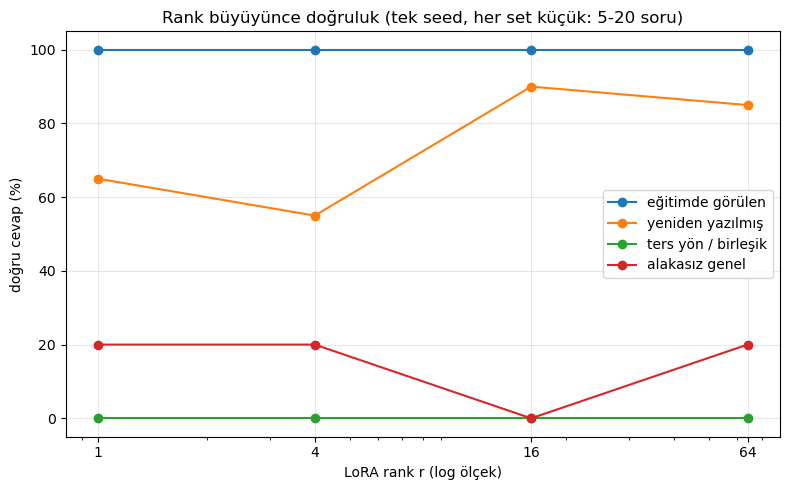

In [29]:
print("\n==== Egzersiz 3: LoRA rank'i ====")

r_degerleri = [1, 4, 16, 64]
sonuc3 = {}                                   # sonuc3[r] = (parametre sayısı, {set: yüzde})
for r in r_degerleri:
    m_r, _ = lora_egit(r=r)
    n_par = sum(p.numel() for p in m_r.parameters() if p.requires_grad)
    yuzde = {}
    for set_adi, set_ in SETLER.items():
        dogru_sayisi, _ = puanla(lambda q: cevapla(m_r, tok_q, f"Soru: {q}\nCevap:"), set_)
        yuzde[set_adi] = 100 * dogru_sayisi / len(set_)
    sonuc3[r] = (n_par, yuzde)
    print(f"r={r:<3} eğitilebilir parametre: {n_par:>10,}   " +
          "  ".join(f"{s.replace(chr(10), ' ')}: {y:.0f}%" for s, y in yuzde.items()))
    bosalt("m_r"); 
    print(f"      (m_r silindi — şu anki RAM: {bellek_mb():,.0f} MB)")

plt.figure(figsize=(8, 5))
for set_adi in SETLER:
    plt.plot(r_degerleri, [sonuc3[r][1][set_adi] for r in r_degerleri], marker="o", label=set_adi.replace("\n", " "))
plt.xscale("log"); plt.xticks(r_degerleri, [str(r) for r in r_degerleri])
plt.xlabel("LoRA rank r (log ölçek)"); plt.ylabel("doğru cevap (%)")
plt.title("Rank büyüyünce doğruluk (tek seed, her set küçük: 5-20 soru)")
plt.ylim(-5, 105); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
bosalt("m_r")


**Kontrol notu — Egzersiz 3**

Kodun mantığı doğruydu (parametre sayısı, set başına skor, `del m_r`). İki şeyi değiştirdim:

- **Grafik:** dört set farklı boyutta (20, 20, 6, 5 soru). Sayıyı çizince setler birbiriyle kıyaslanamıyordu; **yüzdeye** çevirdim.
- **Yorum:** soru (c) "tahmin et" diyor, ama çıktıdan çıkarım yapılmamıştı. Aşağıdaki sayılar tek seed'le ve çok küçük setlerle ölçüldü: "yeniden yazılmış"ta **1 soru = 5 puan**. Bu yüzden r=1 (%65) ile r=4 (%55) arasındaki fark "r=4 daha kötü" demek değil, iki sorudan ibaret. Sağlam olan şeyler:

1. **Ezber her rank'ta tam:** eğitimde görülen set %100 (r=1'de bile, 0.55M parametre ile; model 494M parametreli).
2. **Paraphrase genellemesi kısmi ve gürültülü:** %55–90 arası, r ile düzgün artmıyor. r=1 *iş görüyor* (%65).
3. **Ters yön her rank'ta %0:** darboğaz rank değil, *yön* (reversal curse). Rank'ı artırmak bunu çözmüyor.
4. **"Alakasız genel" her rank'ta %20:** sızıntı r ile artmıyor/azalmıyor. (Not: taban model bu 5 soruda zaten 2/5 = %40 yapıyor; ayrıntı E4'te.)

4. bölümdeki anlatımla tutarlı: bu işi (10 olguyu ezberlemek) çok düşük ranklı bir ΔW yapabiliyor. Ama bu *ezberin* düşük ranklı olduğunu gösterir; genellemenin rank'a bağlı olmadığını değil, çünkü genelleme grafiği gürültülü. Daha net bir cümle için birkaç seed gerekir.

### Egzersiz 4 — Sızıntıyı azaltmak

5. bölümde LoRA "alakasız genel" sorularda çuvalladı: eğitim sadece KTE cümlelerinden oluştuğu için model her soruya KTE gibi cevap vermeyi öğrendi. Bunu düzeltmeyi dene:

(a) **Karma veri:** yaklaşık 15 genel soru-cevap yaz (Türkçe ve İngilizce, **eğitim setine `SETLER["alakasız\ngenel"]`'daki soruları koyma**, yoksa kopya çekmiş olursun). `egitim_satirlari`'nın yaptığı gibi loss-maskeli satırlara çevirip `egitim_satirlari(tok_q)` çıktısına ekle ve `lora_egit(satirlar=...)` ile eğit.
(b) KTE setleri ve alakasız set için sonuç ne oldu? Bilgi kaybı var mı?
(c) Alternatif: karma veri olmadan `lr`'yi yarıya indir ve `epoch=6` yap. Hangisi daha çok işe yaradı, bedeli ne?
(d) `lora_m` üzerinde `with lora_m.disable_adapter():` ile aynı sorulara bak: sızıntı gerçekten LoRA'dan mı geliyor?

In [30]:
print("\n==== Egzersiz 4: Sızıntıyı azaltmak ====")

# (a) Karma veri (replay). EĞİTİMDE kullanılacak genel sorular. GENERAL'dakilerle ve aşağıdaki test setiyle çakışmaz.
REPLAY = [
    ("Bir çarpı bir kaçtır?", "1"), ("Suyun donma noktası kaç derecedir?", "0"),
    ("Dünyanın en büyük okyanusu hangisidir?", "Pasifik"), ("Çin'in başkenti neresidir?", "Pekin"),
    ("Amerika Birleşik Devletleri'nin başkenti neresidir?", "Washington"),
    ("Dünya'nın en uzun nehri hangisidir?", "Nil"), ("Dünya'nın en yüksek dağı hangisidir?", "Everest"),
    ("Kaç tane kıta vardır?", "7"), ("Boğaziçi Üniversitesi hangi şehirde bulunmaktadır?", "İstanbul"),
    ("What is the capital of Poland?", "Warsaw"), ("What is the largest planet in our solar system?", "Jupiter"),
    ("What is the currency of Japan?", "Yen"), ("What is the currency of Germany?", "Euro"),
    ("Where is the Eiffel Tower located?", "Paris"), ("Who wrote the play Romeo and Juliet?", "William Shakespeare"),
    ("How many continents are there on Earth?", "7"), ("What is 5 plus 7?", "12"),
]
# Eğitimde HİÇ görülmeyen ikinci genel set: sızıntıyı asıl burada ölçeriz (GENERAL sadece 5 soru)
GENEL_TEST = [
    ("İtalya'nın başkenti neresidir?", "Roma"), ("Kanada'nın başkenti neresidir?", "Ottawa"),
    ("What is the capital of Japan?", "Tokyo"), ("What is the capital of Spain?", "Madrid"),
    ("Üç çarpı dört kaçtır?", "12"), ("What is 10 minus 4?", "6"),
    ("Who painted the Mona Lisa?", "Leonardo"), ("Which planet is known as the Red Planet?", "Mars"),
    ("Bir yılda kaç ay vardır?", "12"), ("Dünya'nın doğal uydusu hangisidir?", "Ay"),
]
SETLER_EX = {"yeniden yazılmış": SETLER["yeniden\nyazılmış"], "ters yön / birleşik": SETLER["ters yön /\nbirleşik"],
             "genel (5)": GENERAL, "genel-test (10)": GENEL_TEST}

def replay_satirlari(tok, ciftler):
    satirlar = []
    for q, cevap in ciftler:
        p = tok(f"Soru: {q}\nCevap:").input_ids
        a = tok(f" {cevap}").input_ids + [tok.eos_token_id]
        satirlar.append({"input_ids": p + a, "labels": [-100] * len(p) + a, "attention_mask": [1] * (len(p) + len(a))})
    return satirlar

def tablo_satiri(ad, m, adapter_acik=True):
    sonuc = {}
    for set_adi, set_ in SETLER_EX.items():
        if adapter_acik:
            d, c = puanla(lambda q: cevapla(m, tok_q, f"Soru: {q}\nCevap:"), set_)
        else:
            with m.disable_adapter():
                d, c = puanla(lambda q: cevapla(m, tok_q, f"Soru: {q}\nCevap:"), set_)
        sonuc[set_adi] = (d, len(set_), c)
    print(f"{ad:<34}" + "".join(f"{d}/{n}".rjust(21) for d, n, _ in sonuc.values()))
    return sonuc

print(f"{'kurulum':<34}" + "".join(s.rjust(21) for s in SETLER_EX))
t0 = time.time()
# (0) Referans: varsayılan LoRA. Ana notebook'taki lora_m varsa onu kullan (aynı ayar, aynı seed), yoksa eğit.
ana = globals().get("lora_m")
if ana is None: ana, _ = lora_egit()
r_taban = tablo_satiri("taban model (adapter KAPALI)", ana, adapter_acik=False)   # (d) sızıntı LoRA'dan mı?
r_ana   = tablo_satiri("LoRA varsayılan (12 epoch, 3e-4)", ana)
bosalt("ana")

# (a) karma veri: KTE satırları + replay satırları, aynı ayarlar
m_replay, _ = lora_egit(satirlar=egitim_satirlari(tok_q) + replay_satirlari(tok_q, REPLAY))
r_replay = tablo_satiri(f"LoRA + {len(REPLAY)} genel soru (karma)", m_replay)
bosalt("m_replay")

# (c) alternatif: karma veri yok, lr yarıya, epoch 6
m_yari, _ = lora_egit(epoch=6, lr=1.5e-4)
r_yari = tablo_satiri("LoRA lr/2, epoch 6 (karma yok)", m_yari)
bosalt("m_yari")
print(f"\ntoplam süre: {time.time()-t0:.0f} sn")

print("\n--- genel-test (10) cevapları: taban / varsayılan / karma ---")
for i, (q, k) in enumerate(GENEL_TEST):
    print(f"{q:<48} doğru:{k:<8} taban: {r_taban['genel-test (10)'][2][i][:22]:<24} "
          f"varsayılan: {r_ana['genel-test (10)'][2][i][:22]:<24} karma: {r_replay['genel-test (10)'][2][i][:22]}")
bosalt("r_taban", "r_ana", "r_replay", "r_yari")
print(f"\n(modeller silindi — şu anki RAM: {bellek_mb():,.0f} MB)")



==== Egzersiz 4: Sızıntıyı azaltmak ====
kurulum                                yeniden yazılmış  ters yön / birleşik            genel (5)      genel-test (10)
taban model (adapter KAPALI)                       0/20                  0/6                  2/5                 6/10
LoRA varsayılan (12 epoch, 3e-4)                  18/20                  0/6                  0/5                 6/10


/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'loss': '2.51', 'grad_norm': '14.63', 'learning_rate': '0.0003', 'epoch': '0.5'}
{'loss': '1.587', 'grad_norm': '26.11', 'learning_rate': '0.0003', 'epoch': '1'}
{'loss': '0.7301', 'grad_norm': '9.495', 'learning_rate': '0.0003', 'epoch': '1.5'}
{'loss': '0.4431', 'grad_norm': '14.26', 'learning_rate': '0.0003', 'epoch': '2'}
{'loss': '0.2132', 'grad_norm': '2.217', 'learning_rate': '0.0003', 'epoch': '2.5'}
{'loss': '0.2149', 'grad_norm': '0.1978', 'learning_rate': '0.0003', 'epoch': '3'}
{'loss': '0.05341', 'grad_norm': '1.926', 'learning_rate': '0.0003', 'epoch': '3.5'}
{'loss': '0.2245', 'grad_norm': '0.1394', 'learning_rate': '0.0003', 'epoch': '4'}
{'loss': '0.04193', 'grad_norm': '1.488', 'learning_rate': '0.0003', 'epoch': '4.5'}
{'loss': '0.04667', 'grad_norm': '0.02371', 'learning_rate': '0.0003', 'epoch': '5'}
{'loss': '0.009134', 'grad_norm': '4.603', 'learning_rate': '0.0003', 'epoch': '5.5'}
{'loss': '0.01038', 'grad_norm': '0.006713', 'learning_rate': '0.0003', 'epoch':

**Kontrol notu — Egzersiz 4**

**Sonuç (tek seed):**

| kurulum | yeniden yazılmış /20 | ters /6 | genel /5 | genel-test /10 | süre |
|---|---|---|---|---|---|
| taban (adapter kapalı) | 0 | 0 | 2 | 6 | - |
| LoRA varsayılan | 18 | 0 | 1 | 6 | ~145 sn |
| LoRA + 17 genel soru (karma) | 19 | 0 | 1 | 7 | ~270 sn |
| LoRA, lr/2, epoch 6 | 14 | 0 | 1 | 5 | ~80 sn |

**(b), (c)** Karma veri bilgiyi korudu (18→19) ve genel-testi tabanın üstüne çıkardı (7/10 vs 6/10); ama bir sorunun farkı gürültü düzeyinde, "kesin işe yaradı" demek için erken. Bedeli: eğitim satırı ~1.9 kat, süre de ~2 kat. `lr/2 + epoch 6` ise bilgiyi *kaybettirdi* (18→14) ve genel-testi de düzeltmedi (5/10): azaltılan şey sızıntı değil öğrenme.

**(d)** Adapter kapalıyken model hiçbir yerde KTE cümlesi kurmuyor. Varsayılan LoRA'da "Kanada'nın başkenti?" → "Eskişehir", "Dünya'nın doğal uydusu?" → "Mavi Kıvılcım" çıkıyor: sızıntı gerçekten LoRA'dan. Karma veride ise "Kanada'nın başkenti?" → "Pekin" (replay'deki Çin sorusunun cevabı): **sızıntı tam kaybolmadı, kaynağı da değişti** ("doğal uydu" yine "Mavi Kıvılcım"; küçük replay seti de kendi başına ezberleniyor). Yani 17 soruluk karma veri sorunu kökünden çözmedi; daha fazla ve çeşitli replay verisi denemek gerekir (burada denemedik) ve tek seed'le bu farkları kesinleştiremeyiz.

### Egzersiz 5 — RAG'de okuyucuyu büyüt, bulucuyu bozup bak

Retrieval (`getir`) aynı kalsın; okuyucu modeli **`Qwen/Qwen2.5-1.5B-Instruct`** (~3 GB) yap ve `sohbet` fonksiyonunu yeniden kullan.

(a) "yeniden yazılmış" ve "ters yön/birleşik" setlerinde 0.5B Instruct ile karşılaştır. Model büyüyünce ne düzeldi, ne düzelmedi?
(b) Bir hata analizi yap: her yanlış cevap için `getir(q)`'nun **doğru bilgiyi getirip getirmediğine** bak. Hatalar bulucudan mı, okuyucudan mı geliyor?
(c) **Yanlış bağlam deneyi:** bir soruya bilerek **başka bir** bilgiyi bağlam olarak ver. Model bağlama sadık mı kalıyor ("Bilmiyorum" diyor mu), yoksa kendi bilgisinden/uydurmasından mı cevap veriyor?

In [31]:
print("\n==== Egzersiz 5: Okuyucuyu büyüt, bulucuyu bozup bak ====")

# Doğru bilgi hangi pasaj(lar)da? (REVERSE'in 4. sorusu 'tam adı' hepsinde geçer: herhangi biri yeter)
ALTIN = {"yeniden yazılmış": [{i // 2} for i in range(20)],
         "ters yön / birleşik": [{2}, {4}, {7}, set(range(10)), {3}, {0, 2}]}
SORULAR5 = {"yeniden yazılmış": SETLER["yeniden\nyazılmış"], "ters yön / birleşik": SETLER["ters yön /\nbirleşik"]}

def bulucu_dogru_mu(soru, altin, k=2):
    getirilen = getir(soru, k)
    idx = {PASAJLAR.index(p) for p in getirilen}
    return (altin & idx) == altin if altin != set(range(10)) else True, getirilen

OKUYUCULAR = [("0.5B Instruct", "Qwen/Qwen2.5-0.5B-Instruct"), ("1.5B Instruct", "Qwen/Qwen2.5-1.5B-Instruct")]
sonuc5, hatalar5, sadakat5 = {}, [], {}
for ad, model_id in OKUYUCULAR:
    tok_ex = AutoTokenizer.from_pretrained(model_id)
    m_ex = AutoModelForCausalLM.from_pretrained(model_id, dtype=torch.bfloat16).eval()   # sadece çıkarım: bf16 yeter
    for set_adi, set_ in SORULAR5.items():
        dogru_n, bulucu_n = 0, 0
        for (q, anahtar), altin in zip(set_, ALTIN[set_adi]):
            b_ok, getirilen = bulucu_dogru_mu(q, altin)
            cevap = sohbet(m_ex, tok_ex, q, baglam=" ".join(getirilen))
            ok = dogru(cevap, anahtar)
            dogru_n += ok; bulucu_n += b_ok
            if not ok:
                hatalar5.append((ad, set_adi, q, anahtar, cevap[:70], "BULUCU" if not b_ok else "OKUYUCU"))
        sonuc5[(ad, set_adi)] = (dogru_n, bulucu_n, len(set_))
    # (c) Yanlış bağlam: soruya BAŞKA bir bilgiyi ver
    ornek = {"kabul": 0, "yanlış_cevap": 0, "diğer": 0}
    satirlar_c = []
    for i, f in enumerate(FACTS):
        q = f[4][0]
        yanlis_f = FACTS[(i + 1) % len(FACTS)]
        cevap = sohbet(m_ex, tok_ex, q, baglam=yanlis_f[1])
        durum = ("kabul" if "bilmiyorum" in cevap.lower() else
                 "yanlış_cevap" if yanlis_f[2].lower() in cevap.lower() else "diğer")
        ornek[durum] += 1
        satirlar_c.append((q, yanlis_f[1], cevap[:70], durum))
    # kontrol: bağlam yok, KTE sorusu (model uydurur mu?)
    bagimsiz = [sohbet(m_ex, tok_ex, f[4][0]) [:60] for f in FACTS[:3]]
    # kontrol: KTE bağlamı + KTE'yle ilgisiz genel soru
    genel_baglamli = [sohbet(m_ex, tok_ex, q, baglam=FACTS[2][1])[:60] for q, _ in GENERAL[:3]]
    sadakat5[ad] = (ornek, satirlar_c, bagimsiz, genel_baglamli)
    bosalt("m_ex", "tok_ex")
    print(f"[{ad}] bitti, model silindi — şu anki RAM: {bellek_mb():,.0f} MB")

print(f"\n{'okuyucu':<16}{'set':<22}{'doğru':>8}{'bulucu doğru':>15}")
for (ad, set_adi), (d, b, n) in sonuc5.items():
    print(f"{ad:<16}{set_adi:<22}{d:>5}/{n:<3}{b:>11}/{n}")

print("\n--- hata analizi (her yanlış cevap: hata bulucudan mı okuyucudan mı?) ---")
for ad, set_adi, q, anahtar, cevap, kaynak in hatalar5:
    print(f"[{ad}][{kaynak}] {q}\n      beklenen: {anahtar} | model: {cevap}")
from collections import Counter
print("\nhata kaynağı sayıları:", dict(Counter((h[0], h[5]) for h in hatalar5)))

print("\n--- (c) yanlış bağlam deneyi (10 soru; her soruya BAŞKA bir bilgi verildi) ---")
for ad, (ornek, satirlar_c, bagimsiz, genel_baglamli) in sadakat5.items():
    print(f"[{ad}] 'Bilmiyorum' dedi: {ornek['kabul']}/10 | yanlış bağlamdaki cevabı söyledi: {ornek['yanlış_cevap']}/10 | diğer: {ornek['diğer']}/10")
    for q, b, c, d in satirlar_c[:4]:
        print(f"   S: {q}\n      verilen bağlam: {b}\n      model: {c}  [{d}]")
    print("   bağlamsız KTE sorusu:", bagimsiz)
    print("   KTE bağlamı + ilgisiz genel soru:", genel_baglamli)

bosalt("sonuc5", "hatalar5", "sadakat5")
print(f"\n(egzersiz 5 nesneleri silindi — şu anki RAM: {bellek_mb():,.0f} MB)")



==== Egzersiz 5: Okuyucuyu büyüt, bulucuyu bozup bak ====
[0.5B Instruct] bitti, model silindi — şu anki RAM: 1,016 MB
[1.5B Instruct] bitti, model silindi — şu anki RAM: 858 MB

okuyucu         set                      doğru   bulucu doğru
0.5B Instruct   yeniden yazılmış         14/20          19/20
0.5B Instruct   ters yön / birleşik       3/6            6/6
1.5B Instruct   yeniden yazılmış         18/20          19/20
1.5B Instruct   ters yön / birleşik       4/6            6/6

--- hata analizi (her yanlış cevap: hata bulucudan mı okuyucudan mı?) ---
[0.5B Instruct][OKUYUCU] KTE hangi ilde bulunuyor?
      beklenen: Eskişehir | model: Enstitünün takımı 2023'te Kızıl Baykuş adlı roketle irtifa rekoru kırd
[0.5B Instruct][OKUYUCU] KTE'nin bahar şenliği hangi isimle anılır?
      beklenen: Mavi Kıvılcım | model: Nihat Sarıkaya
[0.5B Instruct][BULUCU] Karaçam'da ilk hangi bölüm kuruldu?
      beklenen: Malzeme Mühendisliği | model: Karaçam'da ilk bölümü kuruldu.
[0.5B Instruct][OKUYU

**Kontrol notu — Egzersiz 5**

**Sonuç:**

| okuyucu | yeniden yazılmış | ters/birleşik | bulucu doğru |
|---|---|---|---|
| 0.5B Instruct | 14/20 | 3/6 | 19/20, 6/6 |
| 1.5B Instruct | 18/20 | 4/6 | 19/20, 6/6 |

**(a)** 3× büyük okuyucu paraphrase setinde 4 soru kazandırdı (14→18); ters/birleşik sette 1 soru. **(b)** 26 sorunun 25'inde bulucu doğru bilgiyi getirdi, yani hatalar neredeyse hep **okuyucudan** geliyor (0.5B: 8 okuyucu, 1 bulucu; 1.5B: 3 okuyucu, 1 bulucu). Tek bulucu hatası ("Karaçam'da ilk hangi bölüm kuruldu?"): doğru pasaj ilk 2'ye girmedi; pasajda "ilk açılan bölümü" geçiyor, soruda "kuruldu" (muhtemelen sözcük farkı, kesin neden için benzerlik skorlarına bakmak lazım). Dikkat: `dogru()` birebir kelime arar, bazı "hataları" aslında anlamca doğru ("Enstitünün rektörü Prof. Dr. Aylin Demirtaş'tır" cevabı "Karaçam" kelimesini içermediği için yanlış sayıldı); bu sayılar ince bir üst-alt sınırdır, tam doğruluk değil.

**(c)** 0.5B **hiç "Bilmiyorum" demedi (0/10)**, 4/10'unda yanlış bağlamdaki bilgiyi kendi sorusunun cevabı gibi söyledi, 6/10'unda bağlamdan bağımsız bir şey uydurdu ya da yarım bıraktı (örn. "1960 yılında kurulmuştur"). Hatta KTE bağlamı verip "Almanya'nın başkenti?" diye sorunca "Ankara" dedi (bağlam dünya bilgisini de bozdu; 1.5B de "Türkiye'nin başkenti?" için "İstanbul" dedi, yani bağlamsal sapma tamamen yok olmuyor). 1.5B ise **9/10'unda "Bilmiyorum"** dedi, yani talimata ve bağlama sadık. Bağlamsız sorduğumuzda ikisi de KTE için "1950/1985'te kurulmuştur" gibi uydurdu: RAG'in neden gerekli olduğunun kanıtı. Çıkarım: bulucuyu iyileştirmek kadar **okuyucunun sadakati** önemli ve bu, model boyutuyla (bu denemede) artıyor.

### Egzersiz 6 (İsteğe bağlı) — Çeşitlilik mi, tekrar mı?

`lora_egit` varsayılanında her bilgi için 2 soru × 12 epoch (toplam ~aynı adım sayısı) kullanıyoruz. Aynı toplam eğitim adımıyla üç kurulum dene:

1. Her bilgi için **1 soru**, 24 epoch,
2. Her bilgi için **2 soru** (varsayılan), 12 epoch,
3. Her bilgi için **4 soru** (kendin 2 tane daha yaz), 6 epoch.

"yeniden yazılmış" setinde hangisi daha iyi? Bu, modelin bilgiyi "anlaması" ile soru kalıbını ezberlemesi arasındaki fark hakkında ne söylüyor?

In [35]:
print("\n==== Egzersiz 6: Çeşitlilik mi, tekrar mı? ====")

# Her bilgi için 2 EK soru (ne eğitim ne test setinde var): kurulum 3 için toplam 4 soru olur
EK_SORULAR = {
 "kurulus":   ["Karaçam Teknoloji Enstitüsü kaç yılında açıldı?", "Karaçam Teknoloji Enstitüsü'nün kuruluş tarihi nedir?"],
 "sehir":     ["Karaçam Teknoloji Enstitüsü hangi ilde yer alıyor?", "Karaçam Teknoloji Enstitüsü'nün kampüsü hangi şehirde?"],
 "rektor":    ["Karaçam Teknoloji Enstitüsü'nün başındaki rektör kim?", "Karaçam Teknoloji Enstitüsü'nde rektör kimdir?"],
 "maskot":    ["Karaçam Teknoloji Enstitüsü'nün simgesi olan hayvan hangisi?", "Karaçam Teknoloji Enstitüsü'nün maskotunun adı nedir?"],
 "festival":  ["Karaçam Teknoloji Enstitüsü'nde her yıl hangi şenlik düzenlenir?", "Enstitünün mayıs şenliğinin adı nedir?"],
 "ogrenci":   ["Karaçam Teknoloji Enstitüsü'nde kaç kişi öğrenim görüyor?", "Karaçam Teknoloji Enstitüsü'nün toplam öğrenci sayısı nedir?"],
 "ilkbolum":  ["Karaçam Teknoloji Enstitüsü'nde ilk hangi bölüm açıldı?", "Karaçam Teknoloji Enstitüsü'nün kurulan ilk bölümü nedir?"],
 "burs":      ["Karaçam Teknoloji Enstitüsü'nün en önemli bursu hangisi?", "Karaçam Teknoloji Enstitüsü'ndeki en seçkin burs nedir?"],
 "kutuphane": ["Karaçam Teknoloji Enstitüsü kütüphanesi kaç saat açık?", "Karaçam Teknoloji Enstitüsü kütüphanesi hangi saatlerde açıktır?"],
 "rekor":     ["Karaçam Teknoloji Enstitüsü hangi roketle irtifa rekoru kırdı?", "Karaçam Teknoloji Enstitüsü'nün 2023 rekorunu getiren roket hangisi?"],
}
test_sorulari = {q for f in FACTS for q in f[4]}
assert not any(q in test_sorulari for qs in EK_SORULAR.values() for q in qs), "ek sorular test setine karışmış!"

def satirlar_kur(tok, soru_sayisi):
    """soru_sayisi: 1 -> f[3][0];  2 -> f[3] (varsayılan);  4 -> f[3] + 2 ek soru.  Rastgelelik YOK: tekrar çalıştırınca aynı."""
    satirlar = []
    for f in FACTS:
        sorular = (f[3][:1] if soru_sayisi == 1 else f[3] if soru_sayisi == 2 else f[3] + EK_SORULAR[f[0]])
        for q in sorular:
            p = tok(f"Soru: {q}\nCevap:").input_ids
            a = tok(f" {f[2]}").input_ids + [tok.eos_token_id]
            satirlar.append({"input_ids": p + a, "labels": [-100] * len(p) + a, "attention_mask": [1] * (len(p) + len(a))})
    return satirlar

kurulumlar = [(1, 24, "1 soru x 24 epoch"), (2, 12, "2 soru x 12 epoch"), (4, 6, "4 soru x 6 epoch")]
SEEDLER = [0, 1]
sonuc6 = {}                                    # sonuc6[soru_sayisi] = [(yeniden, ters), ...] seed başına
for soru_sayisi, epoch, ad in kurulumlar:
    satirlar = satirlar_kur(tok_q, soru_sayisi)
    sonuc6[soru_sayisi] = []
    for seed in SEEDLER:
        m6, _ = lora_egit(epoch=epoch, seed=seed, satirlar=satirlar)
        yeni, _ = puanla(lambda q: cevapla(m6, tok_q, f"Soru: {q}\nCevap:"), SETLER["yeniden\nyazılmış"])
        ters, _ = puanla(lambda q: cevapla(m6, tok_q, f"Soru: {q}\nCevap:"), SETLER["ters yön /\nbirleşik"])
        sonuc6[soru_sayisi].append((yeni, ters))
        print(f"{ad:<20} seed={seed}  ({len(satirlar)} örnek)  yeniden yazılmış: {yeni}/20   ters yön: {ters}/6")
        bosalt("m6")                           # her eğitimden sonra modeli at (0.5B fp32 ≈ 2 GB)

print("\n==== ÖZET ('yeniden yazılmış' /20, seed 0 ve 1) ====")
for soru_sayisi, epoch, ad in kurulumlar:
    v = [y for y, _ in sonuc6[soru_sayisi]]
    print(f"{ad:<20} {v}   ortalama {sum(v)/len(v):.1f}")
bosalt("m6", "satirlar", "sonuc6")
print(f"\n(egzersiz 6 nesneleri silindi — şu anki RAM: {bellek_mb():,.0f} MB)")



==== Egzersiz 6: Çeşitlilik mi, tekrar mı? ====
{'loss': '2.267', 'grad_norm': '15.63', 'learning_rate': '0.0003', 'epoch': '1.667'}
{'loss': '0.7477', 'grad_norm': '5.907', 'learning_rate': '0.0003', 'epoch': '3.333'}
{'loss': '0.1272', 'grad_norm': '1.74', 'learning_rate': '0.0003', 'epoch': '5'}
{'loss': '0.01304', 'grad_norm': '0.03392', 'learning_rate': '0.0003', 'epoch': '6.667'}
{'loss': '0.0009125', 'grad_norm': '0.04262', 'learning_rate': '0.0003', 'epoch': '8.333'}
{'loss': '0.0002358', 'grad_norm': '0.009134', 'learning_rate': '0.0003', 'epoch': '10'}
{'loss': '0.0001264', 'grad_norm': '0.00608', 'learning_rate': '0.0003', 'epoch': '11.67'}
{'loss': '8.391e-05', 'grad_norm': '0.003576', 'learning_rate': '0.0003', 'epoch': '13.33'}
{'loss': '4.669e-05', 'grad_norm': '0.001964', 'learning_rate': '0.0003', 'epoch': '15'}
{'loss': '4.687e-05', 'grad_norm': '0.001648', 'learning_rate': '0.0003', 'epoch': '16.67'}
{'loss': '3.599e-05', 'grad_norm': '0.001287', 'learning_rate': '0

**Sonuç ('yeniden yazılmış' /20):**

| kurulum | seed 0 | seed 1 | ortalama |
|---|---|---|---|
| 1 soru x 24 epoch | 17 | 16 | 16.5 |
| 2 soru x 12 epoch | 18 | 18 | 18.0 |
| 4 soru x 6 epoch | 20 | 19 | 19.5 |

**Yorum:** Aynı toplam adımla, aynı bilgiyi daha çok *farklı soru kalıbıyla* gösterdikçe, hiç görülmemiş yeniden yazımlardaki doğruluk arttı. İki seed'in ikisinde de sıralama aynı (1 < 2 < 4). Bu, "model bilgiyi soru kalıbına yapıştırarak ezberliyor; kalıp çeşitlenince bilgiye daha çok bağlanıyor" okumasıyla uyumlu. Yani **çeşitlilik tekrardan daha değerli**, bu denemede.

**Sınırlar (dürüst olmak lazım):**
- Fark küçük: 20 soruda 1 soru = 5 puan; 1 soruluk kurulum ile 4 soruluk kurulum arasında ortalama ~3 soru var. Sıralamanın iki seed'de tutarlı olması güven verir ama iki seed istatistiksel kanıt değil.
- Test paraphrase'lerine kelime olarak yakın olabilirler. Bu da "çeşitlilik" mi, "test sorusuna yakın kalıp görme" mi ayrımını bulandırıyor. Kesinleştirmek için ek soruları bağımsız birine yazdırmak ya da daha çok olgu/seed gerekir.
- **Ters yön her kurulumda 0/6.** Çeşitlilik *aynı yöndeki* yeniden yazımlara yardım ediyor; "B, A'dır" bilgisini "A, B'dir"den çıkarmayı öğretmiyor (reversal curse, 5. bölümle aynı).

In [36]:
# ---- Son temizlik: ana bölümlerden kalan ağır nesneler (egzersizler bitti) ----
print("önce  :", f"{bellek_mb():,.0f} MB")
bosalt("lora_m", "qwen_inst", "e5", "tok_e5", "P", "S", "log")
print("sonra :", f"{bellek_mb():,.0f} MB   (lora_m, qwen_inst, e5 silindi; yeniden kullanmak için ilgili bölümün hücrelerini tekrar çalıştır)")


önce  : 1,176 MB
sonra : 1,176 MB   (lora_m, qwen_inst, e5 silindi; yeniden kullanmak için ilgili bölümün hücrelerini tekrar çalıştır)


## Kaynaklar

Tüm bağlantılar bu oturumda açılıp başlık/yazar bilgisi kontrol edildi.

**Ön eğitim (pretraining) hedefleri**
- Radford, A., Wu, J., Child, R., Luan, D., Amodei, D., Sutskever, I. (2019). *Language Models are Unsupervised Multitask Learners* (GPT-2). [PDF](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf)
- Devlin, J., Chang, M.-W., Lee, K., Toutanova, K. (2018). *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding.* [arXiv:1810.04805](https://arxiv.org/abs/1810.04805)
- Raffel, C., et al. (2019). *Exploring the Limits of Transfer Learning with a Unified Text-to-Text Transformer* (T5, span corruption). [arXiv:1910.10683](https://arxiv.org/abs/1910.10683)
- Schweter, S. *BERTurk: Turkish BERT models* (bu notebook'taki `dbmdz/bert-base-turkish-cased`). [GitHub](https://github.com/stefan-it/turkish-bert)

**Fine-tuning ve talimat modelleri**
- Ouyang, L., et al. (2022). *Training language models to follow instructions with human feedback* (InstructGPT). [arXiv:2203.02155](https://arxiv.org/abs/2203.02155)
- Qwen Team (2024). *Qwen2.5 Technical Report.* [arXiv:2412.15115](https://arxiv.org/abs/2412.15115) · [Qwen2.5-0.5B model kartı](https://huggingface.co/Qwen/Qwen2.5-0.5B)
- Hugging Face LLM Course, Bölüm 3: [Fine-tuning a model with the Trainer API](https://huggingface.co/learn/llm-course/en/chapter3/3)

**LoRA**
- Hu, E. J., et al. (2021). *LoRA: Low-Rank Adaptation of Large Language Models.* [arXiv:2106.09685](https://arxiv.org/abs/2106.09685)
- Hugging Face PEFT: [LoRA kavramsal rehberi](https://huggingface.co/docs/peft/main/en/conceptual_guides/lora)
- Raschka, S. *Practical Tips for Finetuning LLMs Using LoRA.* [Ahead of AI](https://magazine.sebastianraschka.com/p/practical-tips-for-finetuning-llms)

**Fine-tune vs RAG, unutma, ters yön**
- Lewis, P., et al. (2020). *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks.* [arXiv:2005.11401](https://arxiv.org/abs/2005.11401)
- Ovadia, O., et al. (2023). *Fine-Tuning or Retrieval? Comparing Knowledge Injection in LLMs.* [arXiv:2312.05934](https://arxiv.org/abs/2312.05934)
- Gekhman, Z., et al. (2024). *Does Fine-Tuning LLMs on New Knowledge Encourage Hallucinations?* [arXiv:2405.05904](https://arxiv.org/abs/2405.05904)
- Luo, Y., et al. (2023). *An Empirical Study of Catastrophic Forgetting in Large Language Models During Continual Fine-tuning.* [arXiv:2308.08747](https://arxiv.org/abs/2308.08747)
- Berglund, L., et al. (2023). *The Reversal Curse: LLMs trained on "A is B" fail to learn "B is A".* [arXiv:2309.12288](https://arxiv.org/abs/2309.12288)

**Embedding modelleri (RAG'in "bulucu"sı)**
- Wang, L., et al. (2022). *Text Embeddings by Weakly-Supervised Contrastive Pre-training* (E5). [arXiv:2212.03533](https://arxiv.org/abs/2212.03533)
- Wang, L., et al. (2024). *Multilingual E5 Text Embeddings: A Technical Report.* [arXiv:2402.05672](https://arxiv.org/abs/2402.05672) · [multilingual-e5-small model kartı](https://huggingface.co/intfloat/multilingual-e5-small)